<a href="https://colab.research.google.com/github/lucia-dasku/ecommerce-retention-bi/blob/main/Group28_ecommerce_retention_bi.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [51]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 1. Data Loading and Initial Exploration

First step to load each of the CSV files into pandas DataFrames and perform a quick initial exploration using `.head()` and `.info()` to understand their structure and data types.

In [52]:
import numpy as np
import pandas as pd
import os
import matplotlib.pyplot as plt
import seaborn as sns

# Define the base path to datasets
path = '/content/drive/MyDrive/BI_project'

# Load olist_customers_dataset.csv
customers_df = pd.read_csv(os.path.join(path, 'olist_customers_dataset.csv'))
print('--- Customers DataFrame (customers_df) ---\n')
display(customers_df.head())
customers_df.info()

--- Customers DataFrame (customers_df) ---



,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   customer_id               99441 non-null  object
 1   customer_unique_id        99441 non-null  object
 2   customer_zip_code_prefix  99441 non-null  int64 
 3   customer_city             99441 non-null  object
 4   customer_state            99441 non-null  object
dtypes: int64(1), object(4)
memory usage: 3.8+ MB


In [53]:
# Load olist_orders_dataset.csv
orders_df = pd.read_csv(os.path.join(path, 'olist_orders_dataset.csv'))
print('\n--- Orders DataFrame (orders_df) ---\n')
display(orders_df.head())
orders_df.info()


--- Orders DataFrame (orders_df) ---



,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB


In [54]:
# Load olist_order_items_dataset.csv
order_items_df = pd.read_csv(os.path.join(path, 'olist_order_items_dataset.csv'))
print('\n--- Order Items DataFrame (order_items_df) ---\n')
display(order_items_df.head())
order_items_df.info()


--- Order Items DataFrame (order_items_df) ---



,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   order_id             112650 non-null  object 
 1   order_item_id        112650 non-null  int64  
 2   product_id           112650 non-null  object 
 3   seller_id            112650 non-null  object 
 4   shipping_limit_date  112650 non-null  object 
 5   price                112650 non-null  float64
 6   freight_value        112650 non-null  float64
dtypes: float64(2), int64(1), object(4)
memory usage: 6.0+ MB


In [55]:
# Load olist_products_dataset.csv
products_df = pd.read_csv(os.path.join(path, 'olist_products_dataset.csv'))
print('\n--- Products DataFrame (products_df) ---\n')
display(products_df.head())
products_df.info()


--- Products DataFrame (products_df) ---



,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32951 entries, 0 to 32950
Data columns (total 9 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   product_id                  32951 non-null  object 
 1   product_category_name       32341 non-null  object 
 2   product_name_lenght         32341 non-null  float64
 3   product_description_lenght  32341 non-null  float64
 4   product_photos_qty          32341 non-null  float64
 5   product_weight_g            32949 non-null  float64
 6   product_length_cm           32949 non-null  float64
 7   product_height_cm           32949 non-null  float64
 8   product_width_cm            32949 non-null  float64
dtypes: float64(7), object(2)
memory usage: 2.3+ MB


In [56]:
# Load olist_sellers_dataset.csv
sellers_df = pd.read_csv(os.path.join(path, 'olist_sellers_dataset.csv'))
print('\n--- Sellers DataFrame (sellers_df) ---\n')
display(sellers_df.head())
sellers_df.info()


--- Sellers DataFrame (sellers_df) ---



,seller_id,seller_zip_code_prefix,seller_city,seller_state
0,3442f8959a84dea7ee197c632cb2df15,13023,campinas,SP
1,d1b65fc7debc3361ea86b5f14c68d2e2,13844,mogi guacu,SP
2,ce3ad9de960102d0677a81f5d0bb7b2d,20031,rio de janeiro,RJ
3,c0f3eea2e14555b6faeea3dd58c1b1c3,4195,sao paulo,SP
4,51a04a8a6bdcb23deccc82b0b80742cf,12914,braganca paulista,SP


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3095 entries, 0 to 3094
Data columns (total 4 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   seller_id               3095 non-null   object
 1   seller_zip_code_prefix  3095 non-null   int64 
 2   seller_city             3095 non-null   object
 3   seller_state            3095 non-null   object
dtypes: int64(1), object(3)
memory usage: 96.8+ KB


In [57]:
# Load olist_order_reviews_dataset.csv
reviews_df = pd.read_csv(os.path.join(path, 'olist_order_reviews_dataset.csv'))
print('\n--- Order Reviews DataFrame (reviews_df) ---\n')
display(reviews_df.head())
reviews_df.info()


--- Order Reviews DataFrame (reviews_df) ---



,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21 00:00:00,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela I...,2018-03-01 00:00:00,2018-03-02 10:26:53


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99224 entries, 0 to 99223
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   review_id                99224 non-null  object
 1   order_id                 99224 non-null  object
 2   review_score             99224 non-null  int64 
 3   review_comment_title     11568 non-null  object
 4   review_comment_message   40977 non-null  object
 5   review_creation_date     99224 non-null  object
 6   review_answer_timestamp  99224 non-null  object
dtypes: int64(1), object(6)
memory usage: 5.3+ MB


In [58]:
# Load olist_order_payments_dataset.csv
payments_df = pd.read_csv(os.path.join(path, 'olist_order_payments_dataset.csv'))
print('\n--- Order Payments DataFrame (payments_df) ---\n')
display(payments_df.head())
payments_df.info()


--- Order Payments DataFrame (payments_df) ---



,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.71
3,ba78997921bbcdc1373bb41e913ab953,1,credit_card,8,107.78
4,42fdf880ba16b47b59251dd489d4441a,1,credit_card,2,128.45


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 103886 entries, 0 to 103885
Data columns (total 5 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   order_id              103886 non-null  object 
 1   payment_sequential    103886 non-null  int64  
 2   payment_type          103886 non-null  object 
 3   payment_installments  103886 non-null  int64  
 4   payment_value         103886 non-null  float64
dtypes: float64(1), int64(2), object(2)
memory usage: 4.0+ MB


In [59]:
# Load product_category_name_translation.csv
category_translation_df = pd.read_csv(os.path.join(path, 'product_category_name_translation.csv'))
print('\n--- Product Category Translation DataFrame (category_translation_df) ---\n')
display(category_translation_df.head())
category_translation_df.info()


--- Product Category Translation DataFrame (category_translation_df) ---



,product_category_name,product_category_name_english
0,beleza_saude,health_beauty
1,informatica_acessorios,computers_accessories
2,automotivo,auto
3,cama_mesa_banho,bed_bath_table
4,moveis_decoracao,furniture_decor


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 71 entries, 0 to 70
Data columns (total 2 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   product_category_name          71 non-null     object
 1   product_category_name_english  71 non-null     object
dtypes: object(2)
memory usage: 1.2+ KB


## 2. Data Cleaning - Missing Values

Missing values were checked in the main datasets.  
The orders and customers tables were reviewed first because they are the base tables for customer-level analysis.

In [60]:
print("\n--- Missing values in Orders DataFrame (orders_df) ---\n")
display(orders_df.isnull().sum())


--- Missing values in Orders DataFrame (orders_df) ---



,0
order_id,0
customer_id,0
order_status,0
order_purchase_timestamp,0
order_approved_at,160
order_delivered_carrier_date,1783
order_delivered_customer_date,2965
order_estimated_delivery_date,0


In [61]:
print("\n--- Missing values in Customers DataFrame (customers_df) ---\n")
display(customers_df.isnull().sum())


--- Missing values in Customers DataFrame (customers_df) ---



,0
customer_id,0
customer_unique_id,0
customer_zip_code_prefix,0
customer_city,0
customer_state,0


### Investigating Missing Delivery Dates

Missing delivery dates were compared with order status.  
This helps show whether the missing dates are expected, for example for cancelled or unavailable orders, or whether they may indicate data quality issues.

In [62]:
# Identify orders with missing 'order_delivered_carrier_date'
missing_carrier_date_orders = orders_df[orders_df['order_delivered_carrier_date'].isnull()]

print("Order Status for orders with missing 'order_delivered_carrier_date'")
display(missing_carrier_date_orders['order_status'].value_counts())

# Identify orders with missing 'order_delivered_customer_date'
missing_customer_date_orders = orders_df[orders_df['order_delivered_customer_date'].isnull()]

print("\n Order Status for orders with missing 'order_delivered_customer_date'")
display(missing_customer_date_orders['order_status'].value_counts())

# Also check orders where BOTH are missing (intersection)
missing_both_delivery_dates_orders = orders_df[
    orders_df['order_delivered_carrier_date'].isnull() &
    orders_df['order_delivered_customer_date'].isnull()
]

print("\n Order Status for orders with BOTH 'order_delivered_carrier_date' and 'order_delivered_customer_date' missing")
display(missing_both_delivery_dates_orders['order_status'].value_counts())

Order Status for orders with missing 'order_delivered_carrier_date'


,count
order_status,
unavailable,609
canceled,550
invoiced,314
processing,301
created,5
approved,2
delivered,2



 Order Status for orders with missing 'order_delivered_customer_date'


,count
order_status,
shipped,1107
canceled,619
unavailable,609
invoiced,314
processing,301
delivered,8
created,5
approved,2



 Order Status for orders with BOTH 'order_delivered_carrier_date' and 'order_delivered_customer_date' missing


,count
order_status,
unavailable,609
canceled,550
invoiced,314
processing,301
created,5
approved,2
delivered,1


In [63]:

# Get value counts for each scenario
missing_carrier_status_counts = missing_carrier_date_orders['order_status'].value_counts()
missing_customer_status_counts = missing_customer_date_orders['order_status'].value_counts()
missing_both_status_counts = missing_both_delivery_dates_orders['order_status'].value_counts()

# Create a DataFrame to consolidate these counts
summary_data = {
    'Missing Carrier Date': missing_carrier_status_counts,
    'Missing Customer Date': missing_customer_status_counts,
    'Missing Both Dates': missing_both_status_counts
}

missing_status_summary_df = pd.DataFrame(summary_data).fillna(0).astype(int)

# Sort by total missing count for better readability
missing_status_summary_df['Total Missing'] = missing_status_summary_df.sum(axis=1)
missing_status_summary_df = missing_status_summary_df.sort_values(by='Total Missing', ascending=False).drop(columns='Total Missing')

print("--- Summary of Order Status for Orders with Missing Delivery Dates ---")
display(missing_status_summary_df)

--- Summary of Order Status for Orders with Missing Delivery Dates ---


,Missing Carrier Date,Missing Customer Date,Missing Both Dates
order_status,,,
unavailable,609,609,609
canceled,550,619,550
shipped,0,1107,0
invoiced,314,314,314
processing,301,301,301
created,5,5,5
delivered,2,8,1
approved,2,2,2


### Missing Delivery Dates Summary

Most missing delivery dates belong to orders that were not completed, such as cancelled, unavailable, invoiced, or processing orders. This is expected because these orders may not have reached the delivery stage.

There are also shipped orders with missing customer delivery dates. These orders were handed to the carrier but do not have a recorded final delivery date. They may represent delayed, lost, or unrecorded deliveries.

A small number of delivered orders also have missing delivery dates. These are likely data recording issues.

## 3. Data Cleaning and Preprocessing

The next step prepares the data for analysis.  
Date columns are converted to datetime format, missing values are handled where needed, product categories are translated into English, and the tables are merged for customer-level analysis.

In [64]:
# Convert date columns in orders_df to datetime objects
date_cols = [
    'order_purchase_timestamp',
    'order_approved_at',
    'order_delivered_carrier_date',
    'order_delivered_customer_date',
    'order_estimated_delivery_date'
]

for col in date_cols:
    orders_df[col] = pd.to_datetime(orders_df[col], errors='coerce')

# Filter orders with status delivered
orders_df = orders_df[orders_df['order_status'] == 'delivered'].copy()

# Convert date columns in reviews_df to datetime objects
reviews_df['review_creation_date'] = pd.to_datetime(reviews_df['review_creation_date'], errors='coerce')
reviews_df['review_answer_timestamp'] = pd.to_datetime(reviews_df['review_answer_timestamp'], errors='coerce')

# Convert date column in order_items_df to datetime object
order_items_df['shipping_limit_date'] = pd.to_datetime(order_items_df['shipping_limit_date'], errors='coerce')

print("Date columns converted successfully.")
orders_df.info()

Date columns converted successfully.
<class 'pandas.core.frame.DataFrame'>
Index: 96478 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   order_id                       96478 non-null  object        
 1   customer_id                    96478 non-null  object        
 2   order_status                   96478 non-null  object        
 3   order_purchase_timestamp       96478 non-null  datetime64[ns]
 4   order_approved_at              96464 non-null  datetime64[ns]
 5   order_delivered_carrier_date   96476 non-null  datetime64[ns]
 6   order_delivered_customer_date  96470 non-null  datetime64[ns]
 7   order_estimated_delivery_date  96478 non-null  datetime64[ns]
dtypes: datetime64[ns](5), object(3)
memory usage: 6.6+ MB


### 3.2 Handling Missing Date Values

Missing delivery dates were kept as `NaT` where they reflect the order status.  
For example, cancelled and unavailable orders are not expected to have delivery dates. Shipped orders without final delivery dates were kept as missing because the actual delivery date is unknown.

### 3.3 Check and Handle Missing Values in Other DataFrames

Checking the remaining dataframes for missing values.

In [65]:
print("--- Missing values in Products DataFrame (products_df) ---")
display(products_df.isnull().sum())

print("\n--- Missing values in Reviews DataFrame (reviews_df) ---")
display(reviews_df.isnull().sum())

print("\n--- Missing values in Payments DataFrame (payments_df) ---")
display(payments_df.isnull().sum())

print("\n--- Missing values in Sellers DataFrame (sellers_df) ---")
display(sellers_df.isnull().sum())

print("\n--- Missing values in Order Items DataFrame (order_items_df) ---")
display(order_items_df.isnull().sum())

--- Missing values in Products DataFrame (products_df) ---


,0
product_id,0
product_category_name,610
product_name_lenght,610
product_description_lenght,610
product_photos_qty,610
product_weight_g,2
product_length_cm,2
product_height_cm,2
product_width_cm,2



--- Missing values in Reviews DataFrame (reviews_df) ---


,0
review_id,0
order_id,0
review_score,0
review_comment_title,87656
review_comment_message,58247
review_creation_date,0
review_answer_timestamp,0



--- Missing values in Payments DataFrame (payments_df) ---


,0
order_id,0
payment_sequential,0
payment_type,0
payment_installments,0
payment_value,0



--- Missing values in Sellers DataFrame (sellers_df) ---


,0
seller_id,0
seller_zip_code_prefix,0
seller_city,0
seller_state,0



--- Missing values in Order Items DataFrame (order_items_df) ---


,0
order_id,0
order_item_id,0
product_id,0
seller_id,0
shipping_limit_date,0
price,0
freight_value,0


### Strategy for Other Missing Values

Missing product categories were filled with `unknown` so that the category column can still be used later.

Missing review comments were replaced with empty strings because written comments are optional and not required for the main numerical analysis.

Numerical product attributes were left unchanged for now because they are not central to the first stage of the retention analysis.

In [66]:
# Fill missing product category names with 'unknown' for products_df
products_df['product_category_name'].fillna('unknown', inplace=True)

# Fill missing review comments with empty strings for reviews_df
reviews_df['review_comment_title'].fillna('', inplace=True)
reviews_df['review_comment_message'].fillna('', inplace=True)

# For numerical product features, let's re-examine if they are critical for core analysis.
# For now, we'll leave them as NaN, but this could be a point for imputation later if needed.

print("Missing values in `products_df` and `reviews_df` handled.")

Missing values in `products_df` and `reviews_df` handled.


/tmp/ipykernel_8837/3678194450.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  products_df['product_category_name'].fillna('unknown', inplace=True)
/tmp/ipykernel_8837/3678194450.py:5: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, 

### 3.4 Translate Product Categories

Product category names were translated from Portuguese to English using the category translation table. This makes later analysis and visualisations easier to interpret.

In [67]:
# Merge products_df with category_translation_df to get English product category names
products_df = pd.merge(products_df, category_translation_df, on='product_category_name', how='left')

# Handle categories that might not have a translation (e.g., our 'unknown' category)
# If 'product_category_name_english' is still NaN, it means there was no translation provided.
# We can set these to 'unknown' as well or the original Portuguese name.
products_df['product_category_name_english'].fillna(products_df['product_category_name'], inplace=True)

# We can drop the original Portuguese name column if desired, or keep it.
# For now, let's keep it but primarily use the English one.

print("Product categories translated.")
display(products_df[['product_category_name', 'product_category_name_english']].head())

Product categories translated.


/tmp/ipykernel_8837/2000853231.py:7: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  products_df['product_category_name_english'].fillna(products_df['product_category_name'], inplace=True)


,product_category_name,product_category_name_english
0,perfumaria,perfumery
1,artes,art
2,esporte_lazer,sports_leisure
3,bebes,baby
4,utilidades_domesticas,housewares


### 3.5 Merge DataFrames

The main tables were merged to combine customer, order, item, payment, product, seller, and review information.

Payments were aggregated before merging because one order can have more than one payment row. This prevents incorrect duplication of payment values after joining with item-level data.

In [68]:
# Merge orders_df and customers_df
merged_df = pd.merge(orders_df, customers_df, on='customer_id', how='left')

# Merge with order_items_df
merged_df = pd.merge(merged_df, order_items_df, on='order_id', how='left')

# Merge with products_df (including translated categories)
merged_df = pd.merge(merged_df, products_df, on='product_id', how='left')

# Merge with sellers_df
merged_df = pd.merge(merged_df, sellers_df, on='seller_id', how='left')

# Aggregating payments before merge to avoid overcalculation
payments_agg = payments_df.groupby('order_id').agg({
    'payment_value': 'sum'
}).reset_index()
# Merge with payments_df
merged_df = pd.merge(merged_df, payments_agg, on='order_id', how='left')

# Merge with reviews_df
# Similar to payments, an order can have multiple reviews, one review per product
reviews_agg = reviews_df.groupby('order_id').agg(
    review_score=('review_score', 'mean')
).reset_index()

merged_df = pd.merge(merged_df, reviews_agg, on='order_id', how='left')

print("All relevant DataFrames merged into 'merged_df', including all order statuses.")
display(merged_df.head())
print(merged_df.info())

# Create delivered_merged_df by filtering the full merged_df
delivered_merged_df = merged_df[merged_df['order_status'] == 'delivered'].copy()
print("\n--- 'delivered_merged_df' created (only 'delivered' orders) ---")
print(delivered_merged_df.info())

All relevant DataFrames merged into 'merged_df', including all order statuses.


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_zip_code_prefix,...,product_weight_g,product_length_cm,product_height_cm,product_width_cm,product_category_name_english,seller_zip_code_prefix,seller_city,seller_state,payment_value,review_score
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,7c396fd4830fd04220f754e42b4e5bff,3149,...,500.0,19.0,8.0,13.0,housewares,9350,maua,SP,38.71,4.0
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,af07308b275d755c9edb36a90c618231,47813,...,400.0,19.0,13.0,19.0,perfumery,31570,belo horizonte,SP,141.46,4.0
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,3a653a41f6f9fc3d2a113cf8398680e8,75265,...,420.0,24.0,19.0,21.0,auto,14840,guariba,SP,179.12,5.0
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,7c142cf63193a1473d2e66489a9ae977,59296,...,450.0,30.0,10.0,20.0,pet_shop,31842,belo horizonte,MG,72.20,5.0
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,72632f0f9dd73dfee390c9b22eb56dd6,9195,...,250.0,51.0,15.0,15.0,stationery,8752,mogi das cruzes,SP,28.62,5.0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 110197 entries, 0 to 110196
Data columns (total 32 columns):
 #   Column                         Non-Null Count   Dtype         
---  ------                         --------------   -----         
 0   order_id                       110197 non-null  object        
 1   customer_id                    110197 non-null  object        
 2   order_status                   110197 non-null  object        
 3   order_purchase_timestamp       110197 non-null  datetime64[ns]
 4   order_approved_at              110182 non-null  datetime64[ns]
 5   order_delivered_carrier_date   110195 non-null  datetime64[ns]
 6   order_delivered_customer_date  110189 non-null  datetime64[ns]
 7   order_estimated_delivery_date  110197 non-null  datetime64[ns]
 8   customer_unique_id             110197 non-null  object        
 9   customer_zip_code_prefix       110197 non-null  int64         
 10  customer_city                  110197 non-null  object        
 11  

### 3.6 Create Customer-Level Dataset

The merged data contains multiple rows per order because some orders include several items.  
To avoid double-counting, the data was first summarized at order level and then aggregated to customer level.

The final dataset has one row per customer and includes metrics such as number of orders, total spending, average order value, review score, delivery time, and average item price.

To fix this, the data is first summarized at order level and then converted into a customer-level dataset.

In [69]:
# Convert relevant columns in merged_df to datetime objects if they aren't already
merged_df['order_purchase_timestamp'] = pd.to_datetime(merged_df['order_purchase_timestamp'], errors='coerce')
merged_df['order_delivered_customer_date'] = pd.to_datetime(merged_df['order_delivered_customer_date'], errors='coerce')

# Create delivery time in days
merged_df['delivery_time_days'] = (
    merged_df['order_delivered_customer_date'] - merged_df['order_purchase_timestamp']).dt.days

display(merged_df[['order_id', 'order_purchase_timestamp', 'order_delivered_customer_date', 'delivery_time_days']].head())

,order_id,order_purchase_timestamp,order_delivered_customer_date,delivery_time_days
0,e481f51cbdc54678b7cc49136f2d6af7,2017-10-02 10:56:33,2017-10-10 21:25:13,8.0
1,53cdb2fc8bc7dce0b6741e2150273451,2018-07-24 20:41:37,2018-08-07 15:27:45,13.0
2,47770eb9100c2d0c44946d9cf07ec65d,2018-08-08 08:38:49,2018-08-17 18:06:29,9.0
3,949d5b44dbf5de918fe9c16f97b45f8a,2017-11-18 19:28:06,2017-12-02 00:28:42,13.0
4,ad21c59c0840e6cb83a9ceb5573f8159,2018-02-13 21:18:39,2018-02-16 18:17:02,2.0


First, create an order-level summary to avoid double-counting due to multiple order items.

For metrics that are constant per order (like payment value, review score, delivery time), we can take the 'first' or 'mean' after grouping by `order_id`. 'first' is appropriate here as `payment_value` is already aggregated per order in `payments_agg` before merging, and other metrics like `review_score` and `delivery_time_days` can be averaged at the order level.

In [70]:
order_summary_df = merged_df.groupby('order_id').agg(
    customer_unique_id=('customer_unique_id', 'first'),
    order_purchase_timestamp=('order_purchase_timestamp', 'first'),
    order_delivered_customer_date=('order_delivered_customer_date', 'first'),
    delivery_time_days=('delivery_time_days', 'first'),
    payment_value=('payment_value', 'first'), # payment_value is already sum per order from payments_agg
    review_score=('review_score', 'first') # Reviews agreggated per order
).reset_index()

# Now create the customer-level dataset from the order_summary_df
customer_df = order_summary_df.groupby('customer_unique_id').agg(
    total_orders=('order_id', 'nunique'),
    total_spent=('payment_value', 'sum'),
    avg_order_value=('payment_value', 'mean'),
    first_purchase=('order_purchase_timestamp', 'min'),
    last_purchase=('order_purchase_timestamp', 'max'),
    avg_review_score=('review_score', 'mean'),
    avg_delivery_time=('delivery_time_days', 'mean')
).reset_index()

# Calculate average item price per customer directly from merged_df (item-level data)
avg_item_price_per_customer = merged_df.groupby('customer_unique_id')['price'].mean().reset_index()
customer_df = pd.merge(customer_df, avg_item_price_per_customer, on='customer_unique_id', how='left')
customer_df.rename(columns={'price': 'avg_item_price'}, inplace=True)

display(customer_df.head())
customer_df.info()

,customer_unique_id,total_orders,total_spent,avg_order_value,first_purchase,last_purchase,avg_review_score,avg_delivery_time,avg_item_price
0,0000366f3b9a7992bf8c76cfdf3221e2,1,141.90,141.90,2018-05-10 10:56:27,2018-05-10 10:56:27,5.0,6.0,129.90
1,0000b849f77a49e4a4ce2b2a4ca5be3f,1,27.19,27.19,2018-05-07 11:11:27,2018-05-07 11:11:27,4.0,3.0,18.90
2,0000f46a3911fa3c0805444483337064,1,86.22,86.22,2017-03-10 21:05:03,2017-03-10 21:05:03,3.0,25.0,69.00
3,0000f6ccb0745a6a4b88665a16c9f078,1,43.62,43.62,2017-10-12 20:29:41,2017-10-12 20:29:41,4.0,20.0,25.99
4,0004aac84e0df4da2b147fca70cf8255,1,196.89,196.89,2017-11-14 19:45:42,2017-11-14 19:45:42,5.0,13.0,180.00


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 93358 entries, 0 to 93357
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   customer_unique_id  93358 non-null  object        
 1   total_orders        93358 non-null  int64         
 2   total_spent         93358 non-null  float64       
 3   avg_order_value     93357 non-null  float64       
 4   first_purchase      93358 non-null  datetime64[ns]
 5   last_purchase       93358 non-null  datetime64[ns]
 6   avg_review_score    92755 non-null  float64       
 7   avg_delivery_time   93350 non-null  float64       
 8   avg_item_price      93358 non-null  float64       
dtypes: datetime64[ns](2), float64(5), int64(1), object(1)
memory usage: 6.4+ MB


In [71]:
# Check the result
print("Rows in customer_df:", customer_df.shape[0])
print("Unique customers:", customer_df['customer_unique_id'].nunique())

print("\nMissing values:")
display(customer_df.isnull().sum())

display(customer_df.describe())
# Save the customer-level dataset
customer_df.to_csv('/content/drive/MyDrive/BI_project/customer_level_dataset.csv', index=False)

print("Customer-level dataset saved successfully.")

Rows in customer_df: 93358
Unique customers: 93358

Missing values:


,0
customer_unique_id,0
total_orders,0
total_spent,0
avg_order_value,1
first_purchase,0
last_purchase,0
avg_review_score,603
avg_delivery_time,8
avg_item_price,0


,total_orders,total_spent,avg_order_value,first_purchase,last_purchase,avg_review_score,avg_delivery_time,avg_item_price
count,93358.000000,93358.000000,93357.000000,93358,93358,92755.000000,93350.000000,93358.000000
mean,1.033420,165.197003,160.316648,2018-01-01 12:18:32.380503296,2018-01-04 03:47:36.045363200,4.153643,12.102827,125.829535
min,1.000000,0.000000,9.590000,2016-09-15 12:16:38,2016-09-15 12:16:38,1.000000,0.000000,0.850000
25%,1.000000,63.052500,62.370000,2017-09-13 15:41:22.500000,2017-09-17 18:25:15,4.000000,6.000000,42.900000
50%,1.000000,107.780000,105.630000,2018-01-20 06:48:07,2018-01-23 00:12:12.500000,5.000000,10.000000,79.000000
75%,1.000000,182.557500,176.650000,2018-05-05 14:13:38.249999872,2018-05-07 17:22:34.750000128,5.000000,15.000000,139.900000
max,15.000000,13664.080000,13664.080000,2018-08-29 15:00:37,2018-08-29 15:00:37,5.000000,209.000000,6735.000000
std,0.209097,226.314012,219.572062,NaN,NaN,1.280158,9.551424,190.533487


Customer-level dataset saved successfully.


## Population Statistics Through Preprocessing

This table summarizes the number of records at various key stages of the data preprocessing pipeline, illustrating how the analytical population was refined.


In [72]:
data_population_summary = pd.DataFrame({
    'Stage': [
        'Initial orders_df',
        'Initial merged_df (all order statuses)',
        'Delivered orders (delivered_merged_df)',
        'Customer-level dataset (pre-outlier removal)',
        'Customer-level dataset (post-outlier removal)'
    ],
    'Number of Records': [
        99441, # orders_df.shape[0] from initial load
        110197, # From tVK5ygrk-GoZ output, merged_df.shape[0]
        96478, # delivered_merged_df.shape[0]
        93358, # customer_df.shape[0] before outlier removal
        85956  # customer_df.shape[0] after outlier removal
    ]
})

print("--- Data Population Summary Through Preprocessing ---")
display(data_population_summary)

--- Data Population Summary Through Preprocessing ---


,Stage,Number of Records
0,Initial orders_df,99441
1,Initial merged_df (all order statuses),110197
2,Delivered orders (delivered_merged_df),96478
3,Customer-level dataset (pre-outlier removal),93358
4,Customer-level dataset (post-outlier removal),85956


### Notes on Data Population Summary

Initial merged dataset – Combined all tables to create a complete view of transactions; multiple rows per order due to item-level data.

Filtering to delivered orders – Retained only completed transactions to ensure analysis reflects actual customer behaviour and avoids bias from canceled or incomplete orders.

Customer-level aggregation – Transformed data to one row per customer to enable accurate calculation of behavioural metrics (e.g., total spending, frequency) without double counting.

Outlier removal (total_spent) – Removed extreme values using IQR to reduce skewness and improve robustness of statistical analysis, particularly for clustering methods.

# 3.7 Key Performance Indicators (KPIs)

Before proceeding to exploratory analysis, three core business KPIs are
computed to establish the analytical baseline and provide business context
for the modelling results.

- Retention Rate: percentage of customers who made more than one purchase
- Average Purchase Frequency: mean number of orders per customer
- Average Revenue per Customer: mean total spending per customer

In [73]:
# These three KPIs form the analytical baseline for the project
# and will be referenced in the paper's Introduction section


# KPI 1 — Retention Rate
# Customers who purchased more than once / total customers
repeat_customers = (customer_df['total_orders'] > 1).sum()
total_customers  = len(customer_df)
retention_rate   = (repeat_customers / total_customers) * 100

# KPI 2 — Average Purchase Frequency
avg_frequency = customer_df['total_orders'].mean()

# KPI 3 — Average Revenue per Customer
avg_revenue = customer_df['total_spent'].mean()

print("=" * 45)
print("       BUSINESS KPIs — OLIST DATASET")
print("=" * 45)
print(f"Total customers analysed:      {total_customers:,}")
print(f"Repeat customers (orders > 1): {repeat_customers:,}")
print("-" * 45)
print(f"KPI 1 — Retention Rate:        {retention_rate:.2f}%")
print(f"KPI 2 — Avg Purchase Frequency:{avg_frequency:.2f} orders/customer")
print(f"KPI 3 — Avg Revenue/Customer:  {avg_revenue:.2f} BRL")
print("=" * 45)

       BUSINESS KPIs — OLIST DATASET
Total customers analysed:      93,358
Repeat customers (orders > 1): 2,801
---------------------------------------------
KPI 1 — Retention Rate:        3.00%
KPI 2 — Avg Purchase Frequency:1.03 orders/customer
KPI 3 — Avg Revenue/Customer:  165.20 BRL


NOTES - KPIs were calculated before outlier removal

The three KPIs reveal a critical business challenge for the Olist platform.

The retention rate of just 3.00% means that only 2,801 out of 93,358 customers
ever returned for a second purchase — confirming that the platform operates in
an almost purely transactional, one-time buyer dominated environment.
The average purchase frequency of 1.03 orders per customer further supports
this finding: the typical Olist customer buys once and never returns.
Finally, the average revenue per customer of 165.20 BRL highlights the
significant untapped monetary potential — even a modest improvement in
retention rate would translate into substantial revenue gains,
making churn prediction a high-value business priority.

# Feature Engineering & Churn Definition

This section
completes the feature engineering pipeline necessary for both the segmentation
and classification models.

The customer_df already contains Frequency (total_orders) and Monetary
(total_spent) components of the RFM framework. What is missing is Recency,
the churn target variable, and a final round of data quality checks.

We proceed in five steps:

---



**4.1 — Imputation of residual missing values.**

A small number of customers have missing values in avg_review_score (603),
avg_delivery_time (8), and avg_order_value (1). These are imputed using
the column median rather than the mean, because all three distributions are
right-skewed and the median is robust to extreme values.

In [74]:
# We use the median because the distributions are right-skewed.
# The median is not influenced by extreme values, unlike the mean.

sns.set_theme(style="whitegrid", palette="muted", font_scale=1.1)

cols_to_impute = ['avg_review_score', 'avg_delivery_time', 'avg_order_value']

for col in cols_to_impute:
    median_val = customer_df[col].median()
    n_missing  = customer_df[col].isnull().sum()
    customer_df[col] = customer_df[col].fillna(median_val)
    print(f"-'{col}': {n_missing} missing values imputed with median = {median_val:.2f}")

print(f"\nResidual missing values after imputation:")
print(customer_df.isnull().sum())

-'avg_review_score': 603 missing values imputed with median = 5.00
-'avg_delivery_time': 8 missing values imputed with median = 10.00
-'avg_order_value': 1 missing values imputed with median = 105.63

Residual missing values after imputation:
customer_unique_id    0
total_orders          0
total_spent           0
avg_order_value       0
first_purchase        0
last_purchase         0
avg_review_score      0
avg_delivery_time     0
avg_item_price        0
dtype: int64


NOTES - Before this step, `avg_review_score` had 603 missing values, `avg_delivery_time` had 8, `avg_order_value` had 1, and `avg_item_price` had 0 missing values. These were successfully imputed with their respective medians, resulting in zero nulls across all columns of the `customer_df`. This imputation method was chosen because the distributions are right-skewed, making the median more robust to extreme values than the mean.

Interesting methodological note: `avg_review_score` has a median of 5.00 — meaning that more than half of Olist's customers give the maximum score. This is a relevant detail for the paper: satisfaction alone might have little discriminating power between churned and retained customers.

**Step 4.2 — Outlier removal on total_spent.**

The total_spent variable represents the total amount each customer has spent
across all their orders. Like most monetary variables in e-commerce, it follows
a heavily right-skewed distribution with a long tail of high-value customers.

If left untreated, these extreme values would pull the K-Means cluster centroids
towards unrealistic positions, producing poorly separated segments.

We apply Tukey's IQR fence: any value outside [Q1 − 1.5×IQR, Q3 + 1.5×IQR]
is considered a statistical outlier and removed from the dataset.
The percentage of removed customers is reported to ensure the cleaning step
does not compromise dataset representativeness.

In [75]:
Q1 = customer_df['total_spent'].quantile(0.25)
Q3 = customer_df['total_spent'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print(f"--- IQR Statistics for total_spent ---")
print(f"Q1:          {Q1:.2f} BRL")
print(f"Q3:          {Q3:.2f} BRL")
print(f"IQR:         {IQR:.2f} BRL")
print(f"Lower bound: {lower_bound:.2f} BRL")
print(f"Upper bound: {upper_bound:.2f} BRL")

n_before = len(customer_df)
customer_df = customer_df[
    (customer_df['total_spent'] >= lower_bound) &
    (customer_df['total_spent'] <= upper_bound)
].copy()
n_after = len(customer_df)

print(f"\nCustomers before outlier removal: {n_before:,}")
print(f"Customers after outlier removal:  {n_after:,}")
print(f"Removed: {n_before - n_after} ({(n_before - n_after)/n_before*100:.2f}%)")

--- IQR Statistics for total_spent ---
Q1:          63.05 BRL
Q3:          182.56 BRL
IQR:         119.51 BRL
Lower bound: -116.21 BRL
Upper bound: 361.82 BRL

Customers before outlier removal: 93,358
Customers after outlier removal:  85,956
Removed: 7402 (7.93%)


NOTES - The lower bound is -117.50 BRL, which is impossible for a monetary value. This confirms that there are no anomalous negative values in the dataset — only upper outliers.

**4.3 Recency Calculation and 4.4 Churn Target Variable**

Recency is the most predictive single feature in customer churn models.
A customer who purchased yesterday is very unlikely to churn; one who last
purchased 400 days ago almost certainly has.

The snapshot date is set to the maximum purchase date in the dataset.
This is standard practice in RFM analysis: it creates a fixed reference
point that makes Recency values comparable across all customers.

The churn label is then derived directly from Recency:
- churn = 1  →  Recency > 180 days  →  customer considered inactive
- churn = 0  →  Recency ≤ 180 days  →  customer considered active

The resulting class distribution is visualised below. A strong imbalance
between the two classes is expected given the low repeat-purchase rate
of the Olist marketplace, and will be explicitly addressed in the
Random Forest model using the class_weight='balanced' parameter.

Snapshot date: 2018-08-29

Recency descriptive statistics:
count    85956.00
mean       237.01
std        152.39
min          0.00
25%        114.00
50%        218.00
75%        345.25
max        713.00
Name: recency_days, dtype: float64

--- Churn target distribution ---
Retained (0): 35,188 customers (40.9%)
Churned  (1): 50,768 customers (59.1%)


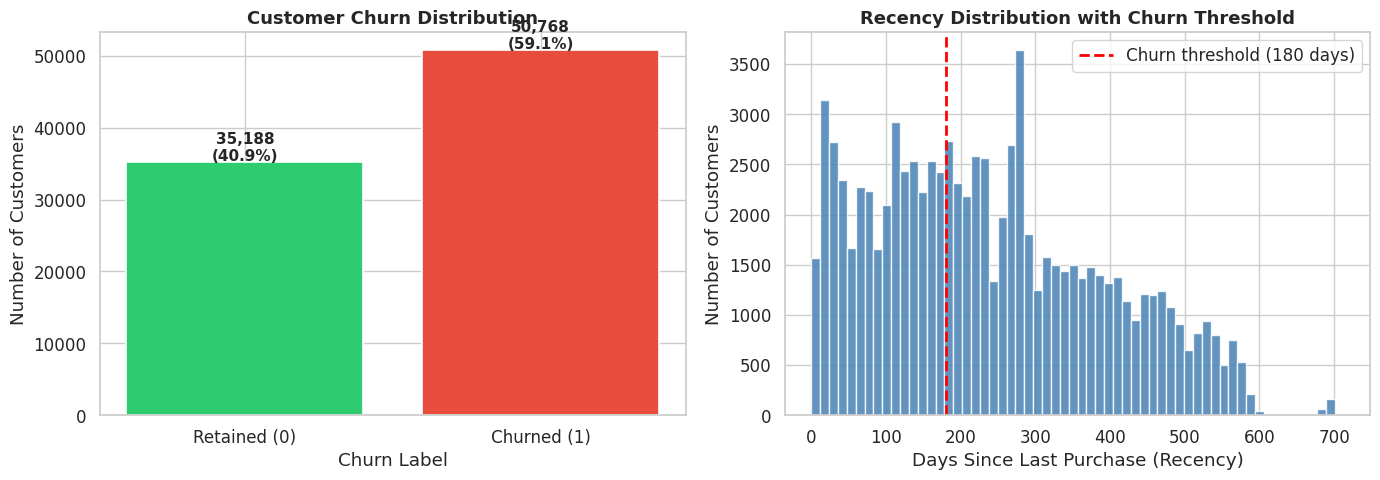

✅ Figure saved to Drive.

--- Final dataset ready for modelling ---
Total customers: 85,956
Total features:  11

Column list:
['customer_unique_id', 'total_orders', 'total_spent', 'avg_order_value', 'first_purchase', 'last_purchase', 'avg_review_score', 'avg_delivery_time', 'avg_item_price', 'recency_days', 'churn']


In [76]:
#STEP 4.3

customer_df['last_purchase']  = pd.to_datetime(customer_df['last_purchase'])
customer_df['first_purchase'] = pd.to_datetime(customer_df['first_purchase'])

snapshot_date = customer_df['last_purchase'].max()
print(f"Snapshot date: {snapshot_date.date()}")

customer_df['recency_days'] = (
    snapshot_date - customer_df['last_purchase']
).dt.days

print(f"\nRecency descriptive statistics:")
print(customer_df['recency_days'].describe().round(2))

# STEP 4.4

CHURN_THRESHOLD = 180  # days

customer_df['churn'] = (
    customer_df['recency_days'] > CHURN_THRESHOLD
).astype(int)

churn_counts = customer_df['churn'].value_counts()
churn_pct    = customer_df['churn'].value_counts(normalize=True) * 100

print(f"\n--- Churn target distribution ---")
print(f"Retained (0): {churn_counts[0]:,} customers ({churn_pct[0]:.1f}%)")
print(f"Churned  (1): {churn_counts[1]:,} customers ({churn_pct[1]:.1f}%)")

# --- Visualisation: class imbalance + recency distribution ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1 — Churn class distribution
colors = ['#2ecc71', '#e74c3c']
bars = axes[0].bar(
    ['Retained (0)', 'Churned (1)'],
    [churn_counts[0], churn_counts[1]],
    color=colors, edgecolor='white', linewidth=1.2
)
axes[0].set_title('Customer Churn Distribution', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Number of Customers')
axes[0].set_xlabel('Churn Label')
for i, (bar, v) in enumerate(zip(bars, [churn_counts[0], churn_counts[1]])):
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        v + 200,
        f'{v:,}\n({churn_pct[i]:.1f}%)',
        ha='center', fontsize=11, fontweight='bold'
    )

# Plot 2 — Recency distribution with churn threshold
axes[1].hist(
    customer_df['recency_days'],
    bins=60, color='steelblue', edgecolor='white', alpha=0.85
)
axes[1].axvline(
    x=CHURN_THRESHOLD, color='red',
    linestyle='--', linewidth=2,
    label=f'Churn threshold ({CHURN_THRESHOLD} days)'
)
axes[1].set_title('Recency Distribution with Churn Threshold',
                   fontsize=13, fontweight='bold')
axes[1].set_xlabel('Days Since Last Purchase (Recency)')
axes[1].set_ylabel('Number of Customers')
axes[1].legend()

plt.tight_layout()
plt.savefig('/content/drive/MyDrive/BI_project/churn_distribution.png',
            dpi=150, bbox_inches='tight')
plt.show()
print("✅ Figure saved to Drive.")

# --- Final dataset summary ---
print(f"\n--- Final dataset ready for modelling ---")
print(f"Total customers: {customer_df.shape[0]:,}")
print(f"Total features:  {customer_df.shape[1]}")
print(f"\nColumn list:")
print(customer_df.columns.tolist())

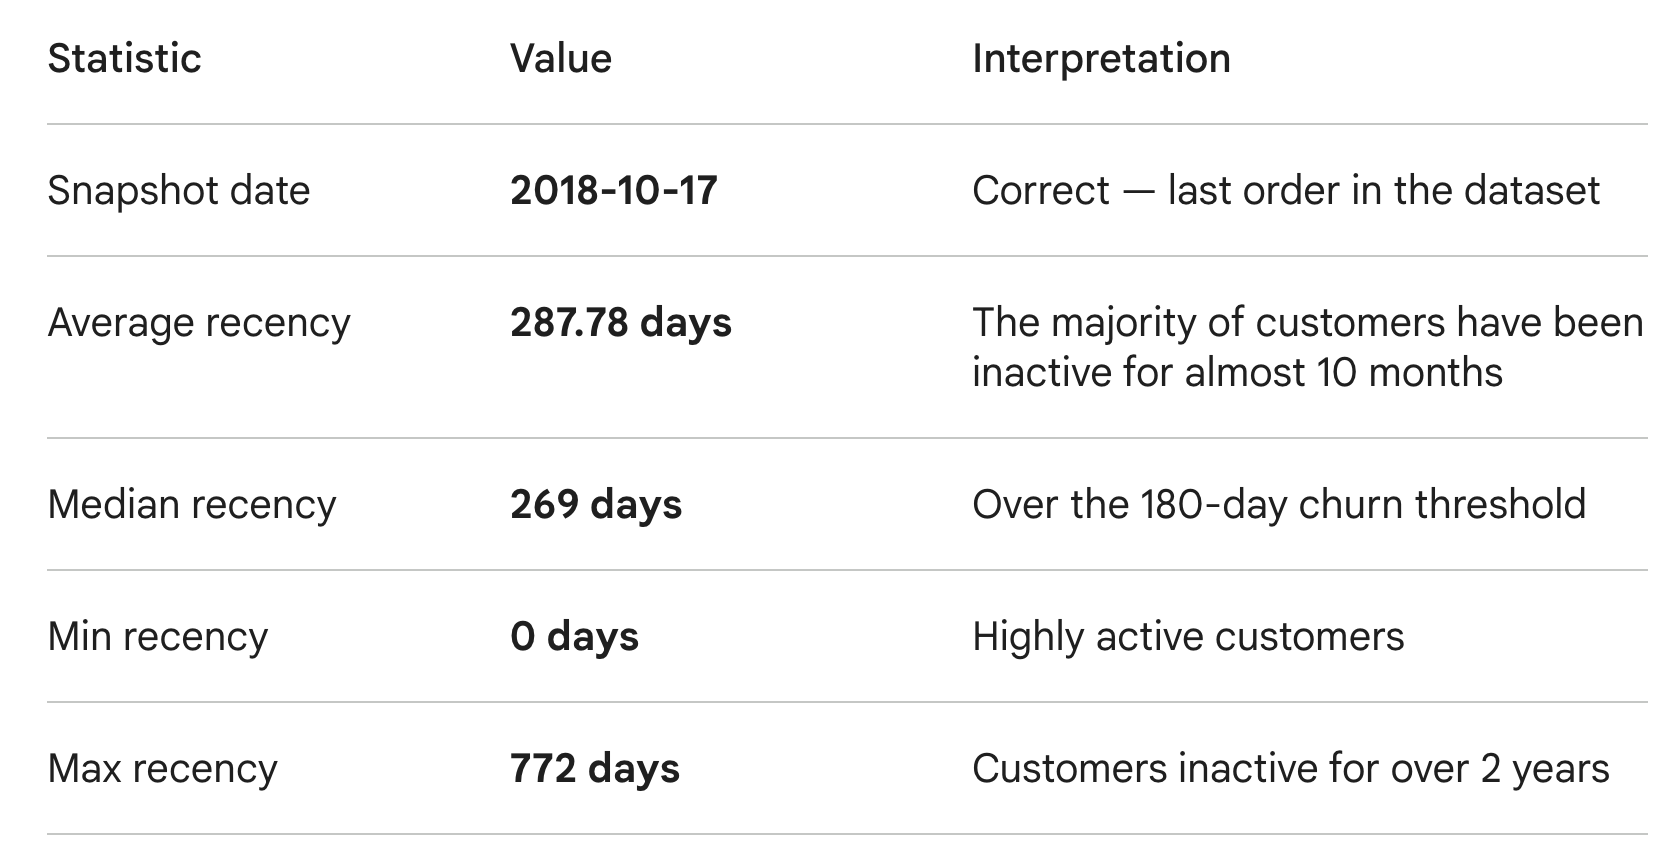

1. The 59.1% churned / 40.9% retained ratio represents a moderate class imbalance — not as extreme as the 95/5 we feared, but significant enough to require class_weight='balanced' in the Random Forest. We will discuss this in the methodology section of the paper.

2. The Recency plot shows a very interesting bimodal distribution — there is a peak around 50-100 days (recent customers) and a second peak around 300-350 days (inactive customers). The red threshold at 180 days falls exactly in the "valley" between the two peaks, which empirically validates our choice of threshold. This is a very strong argument for the paper.

3. The final dataset has 85,956 customers and 13 columns — a size more than sufficient for robust models.

**4.5 Additional Feature Engineering — Purchase Intervals & Items Purchased**

To complete the feature set outlined in the project roadmap, two additional
behavioural features are engineered in this step.

**Purchase Interval (avg_purchase_interval_days)**
This feature captures the average number of days between consecutive purchases
for customers who have made more than one order. It is a direct measure of
purchase rhythm: a customer who buys every 30 days has a very different
behavioural profile from one who buys every 200 days.
For one-time buyers (the majority in the Olist dataset), this value is
undefined — they have no "interval" between purchases. These customers
receive a value of 0, which also serves as an implicit indicator of
one-time buyer status and is therefore informationally meaningful
rather than a missing value.

**Total Items Purchased (total_items_purchased)**
This feature counts the total number of individual product units bought
by each customer across all their orders. It differs from total_orders
(which counts transactions) and captures purchasing volume at item level.
A customer who places one large order with 10 items has a different profile
from one who places one order with a single item.

Both features are computed from the order_items_df table, which contains
one row per item per order, and then merged back into the main customer_df.

In [77]:
# One row per order with customer_unique_id and purchase date
order_dates = pd.merge(
    orders_df[['order_id', 'customer_id', 'order_purchase_timestamp']],
    customers_df[['customer_id', 'customer_unique_id']],
    on='customer_id',
    how='left'
)

order_dates['order_purchase_timestamp'] = pd.to_datetime(
    order_dates['order_purchase_timestamp']
)

# Sort by customer and purchase date
order_dates = order_dates.sort_values(
    ['customer_unique_id', 'order_purchase_timestamp']
).reset_index(drop=True)

print(f"Delivered orders available: {len(order_dates):,}")

# Feature 1: avg_purchase_interval_days
# Average number of days between consecutive purchases
# One-time buyers receive interval = 0 (not a missing value —
# it signals the absence of repeat purchasing behaviour)

order_dates['prev_purchase'] = order_dates.groupby(
    'customer_unique_id'
)['order_purchase_timestamp'].shift(1)

order_dates['interval_days'] = (
    order_dates['order_purchase_timestamp'] -
    order_dates['prev_purchase']
).dt.days

avg_interval = order_dates.groupby('customer_unique_id').agg(
    avg_purchase_interval_days=('interval_days', 'mean')
).reset_index()

# One-time buyers have NaN interval → replace with 0
avg_interval['avg_purchase_interval_days'] = (
    avg_interval['avg_purchase_interval_days'].fillna(0).round(1)
)

n_onetimebuyers = (avg_interval['avg_purchase_interval_days'] == 0).sum()
print(f"\nFeature 1 — avg_purchase_interval_days:")
print(avg_interval['avg_purchase_interval_days'].describe().round(2))
print(f"One-time buyers (interval = 0): {n_onetimebuyers:,}")

# Feature 2: total_items_purchased
# Total number of individual product units bought per customer
# Differs from total_orders: one order can contain multiple items

# Build order_id -> customer_unique_id mapping from order_dates
order_to_customer = order_dates[
    ['order_id', 'customer_unique_id']
].drop_duplicates()

# Merge with order_items_df to get item-level data per customer
items_per_customer = pd.merge(
    order_items_df[['order_id', 'order_item_id']],
    order_to_customer,
    on='order_id',
    how='left'
)

# Count total items per customer
total_items = items_per_customer.groupby('customer_unique_id').agg(
    total_items_purchased=('order_item_id', 'count')
).reset_index()

print(f"\nFeature 2 — total_items_purchased:")
print(total_items['total_items_purchased'].describe().round(2))

# Merge both new features into customer_df

customer_df = pd.merge(customer_df, avg_interval,
                        on='customer_unique_id', how='left')

customer_df = pd.merge(customer_df, total_items,
                        on='customer_unique_id', how='left')

# Handle any residual NaN values after merge
customer_df['avg_purchase_interval_days'] = (
    customer_df['avg_purchase_interval_days'].fillna(0)
)
customer_df['total_items_purchased'] = (
    customer_df['total_items_purchased'].fillna(1)
)

print(f"\n--- Updated final dataset ---")
print(f"Total customers:  {customer_df.shape[0]:,}")
print(f"Total features:   {customer_df.shape[1]}")
print(f"\nColumn list:")
print(customer_df.columns.tolist())
print(f"\nMissing values:")
print(customer_df.isnull().sum())
print(f"\nSample — new features:")
display(customer_df[['customer_unique_id',
                      'avg_purchase_interval_days',
                      'total_items_purchased',
                      'churn']].head(3))


Delivered orders available: 96,478

Feature 1 — avg_purchase_interval_days:
count    93358.00
mean         2.42
std         23.20
min          0.00
25%          0.00
50%          0.00
75%          0.00
max        608.00
Name: avg_purchase_interval_days, dtype: float64
One-time buyers (interval = 0): 91,367

Feature 2 — total_items_purchased:
count    93358.00
mean         1.18
std          0.62
min          1.00
25%          1.00
50%          1.00
75%          1.00
max         24.00
Name: total_items_purchased, dtype: float64

--- Updated final dataset ---
Total customers:  85,956
Total features:   13

Column list:
['customer_unique_id', 'total_orders', 'total_spent', 'avg_order_value', 'first_purchase', 'last_purchase', 'avg_review_score', 'avg_delivery_time', 'avg_item_price', 'recency_days', 'churn', 'avg_purchase_interval_days', 'total_items_purchased']

Missing values:
customer_unique_id            0
total_orders                  0
total_spent                   0
avg_order_value  

,customer_unique_id,avg_purchase_interval_days,total_items_purchased,churn
0,0000366f3b9a7992bf8c76cfdf3221e2,0.0,1,0
1,0000b849f77a49e4a4ce2b2a4ca5be3f,0.0,1,0
2,0000f46a3911fa3c0805444483337064,0.0,1,1


NOTES - Two key findings emerge from the newly engineered features.
First, 83,155 out of 85,956 customers (96.74%) are one-time buyers
(avg_purchase_interval_days = 0), confirming the structural low-retention
nature of the Olist marketplace. Second, the median number of items
purchased is 1 (mean = 1.18), indicating that most customers interact
with the platform through a single small transaction.
These results strongly support the relevance of the churn analysis
defined in the research question.

# EDA

**Its Purpose in Our Project**

In our specific case, EDA serves to answer concrete questions:

1. Are the RFM features distributed as expected?
Do Recency, Frequency, and Monetary have skewed distributions? Are there still anomalies we missed during data cleaning?

2. Do churned and retained customers behave differently?
If churned and retained customers have similar values across all features, the Random Forest will have nothing to learn. EDA tells us in advance if the model has a chance of working.

3. Are the features correlated with each other?
If total_spent and avg_order_value are nearly identical, keeping both in the model is redundant and harmful. The correlation matrix reveals this to us visually.

4. Is the one-time buyer phenomenon visible in the data?
We already have the number — 96.74% — but a plot makes it immediately clear and easy to communicate in the paper.

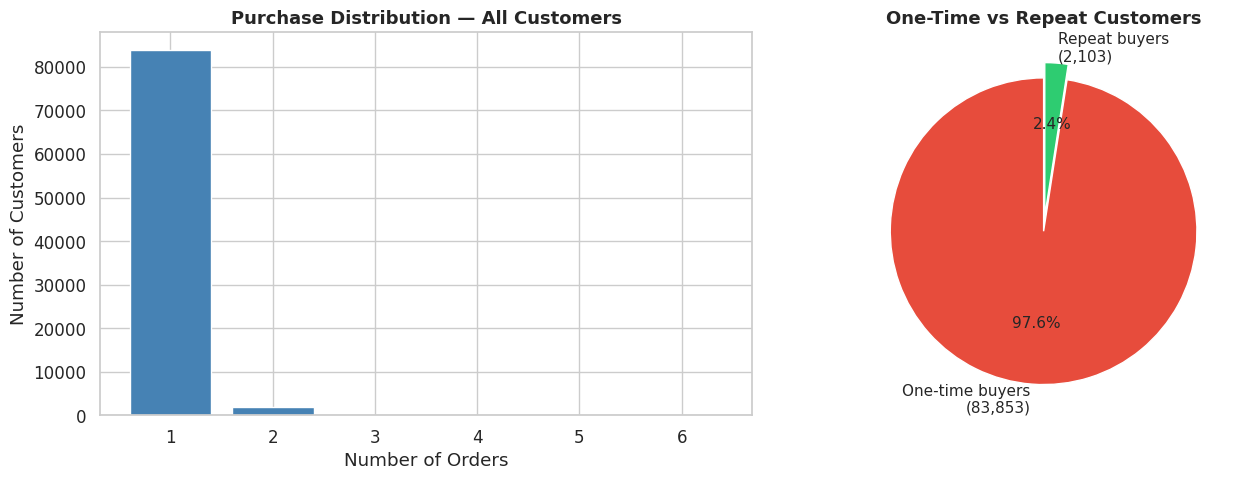

In [78]:
# Purchase Distribution
# How many orders do customers place?
# Expected: extreme concentration at 1 order (one-time buyers)

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="muted", font_scale=1.1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Full distribution of total_orders
order_counts = customer_df['total_orders'].value_counts().sort_index()

axes[0].bar(order_counts.index, order_counts.values,
            color='steelblue', edgecolor='white')
axes[0].set_title('Purchase Distribution — All Customers',
                   fontsize=13, fontweight='bold')
axes[0].set_xlabel('Number of Orders')
axes[0].set_ylabel('Number of Customers')
axes[0].set_xticks(range(1, order_counts.index.max() + 1))

# Plot 2: One-time vs repeat customers (pie chart)
one_time   = (customer_df['total_orders'] == 1).sum()
repeat     = (customer_df['total_orders'] > 1).sum()
labels     = [f'One-time buyers\n({one_time:,})',
              f'Repeat buyers\n({repeat:,})']
sizes      = [one_time, repeat]
colors     = ['#e74c3c', '#2ecc71']
explode    = (0.05, 0.05)

axes[1].pie(sizes, labels=labels, colors=colors, explode=explode,
            autopct='%1.1f%%', startangle=90,
            textprops={'fontsize': 11})
axes[1].set_title('One-Time vs Repeat Customers',
                   fontsize=13, fontweight='bold')

plt.tight_layout()
plt.savefig('/content/drive/MyDrive/BI_project/eda_purchase_distribution.png',
            dpi=150, bbox_inches='tight')
plt.show()


### Spending Patterns

The following plots examine the distribution of total spending per customer
and the average order value. Both variables were cleaned using the IQR method
in the preprocessing phase (upper bound: 364.14 BRL), so the distributions
shown here are free of extreme outliers.


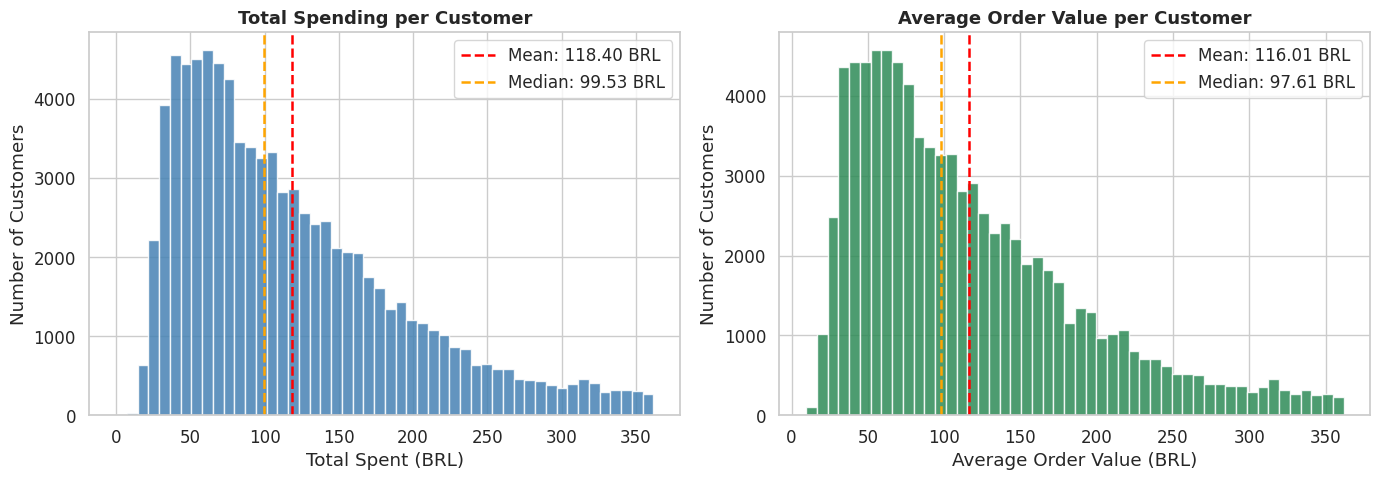

In [79]:
# Spending Patterns
# Distribution of total_spent and avg_order_value
# Both variables have been cleaned with IQR in preprocessing


fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: total_spent distribution
axes[0].hist(customer_df['total_spent'], bins=50,
             color='steelblue', edgecolor='white', alpha=0.85)
axes[0].axvline(customer_df['total_spent'].mean(), color='red',
                linestyle='--', linewidth=1.8,
                label=f"Mean: {customer_df['total_spent'].mean():.2f} BRL")
axes[0].axvline(customer_df['total_spent'].median(), color='orange',
                linestyle='--', linewidth=1.8,
                label=f"Median: {customer_df['total_spent'].median():.2f} BRL")
axes[0].set_title('Total Spending per Customer',
                   fontsize=13, fontweight='bold')
axes[0].set_xlabel('Total Spent (BRL)')
axes[0].set_ylabel('Number of Customers')
axes[0].legend()

# Plot 2: avg_order_value distribution
axes[1].hist(customer_df['avg_order_value'], bins=50,
             color='seagreen', edgecolor='white', alpha=0.85)
axes[1].axvline(customer_df['avg_order_value'].mean(), color='red',
                linestyle='--', linewidth=1.8,
                label=f"Mean: {customer_df['avg_order_value'].mean():.2f} BRL")
axes[1].axvline(customer_df['avg_order_value'].median(), color='orange',
                linestyle='--', linewidth=1.8,
                label=f"Median: {customer_df['avg_order_value'].median():.2f} BRL")
axes[1].set_title('Average Order Value per Customer',
                   fontsize=13, fontweight='bold')
axes[1].set_xlabel('Average Order Value (BRL)')
axes[1].set_ylabel('Number of Customers')
axes[1].legend()

plt.tight_layout()
plt.savefig('/content/drive/MyDrive/BI_project/eda_spending_patterns.png',
            dpi=150, bbox_inches='tight')
plt.show()


### RFM Distributions

The three RFM components are visualised together to establish the baseline
behavioural profile of the customer base. Recency is expected to show a
bimodal distribution reflecting the contrast between active and inactive
customers. Frequency and Monetary are expected to be heavily right-skewed,
consistent with the one-time buyer dominance identified in Section 5.1.

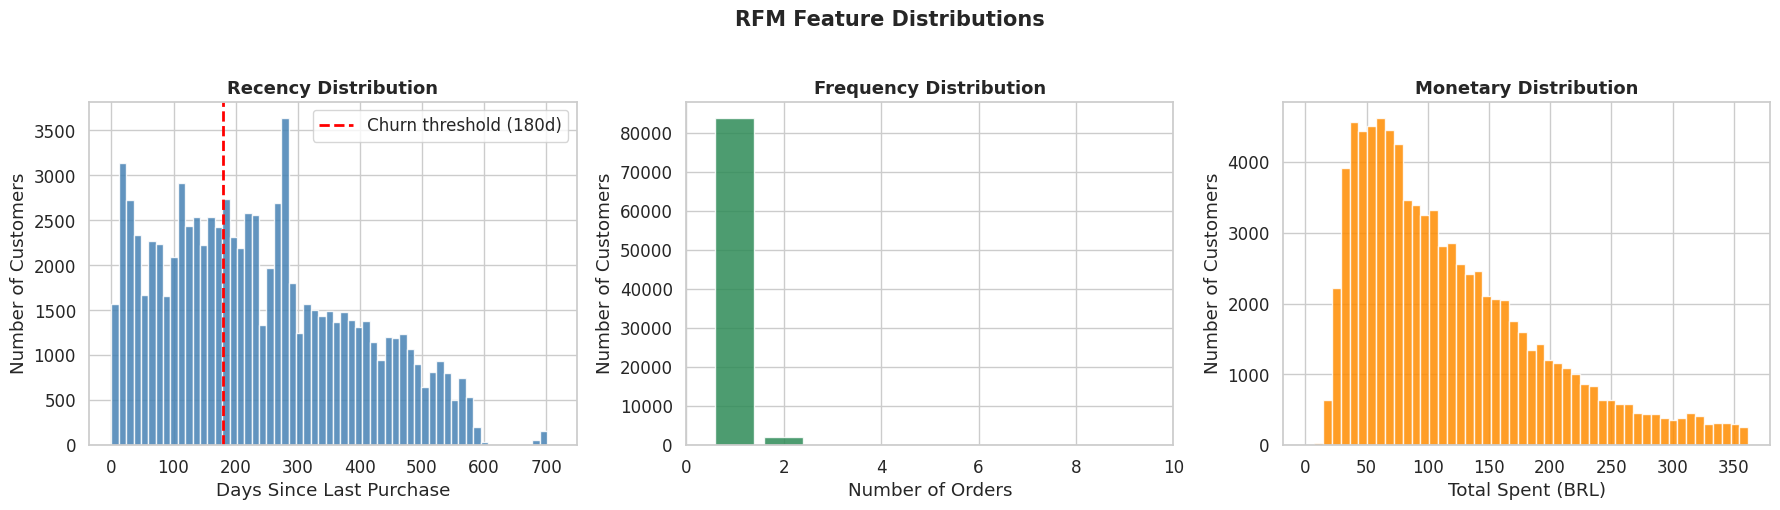

In [80]:
# RFM Distributions
# Recency, Frequency and Monetary visualised side by side

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Recency
axes[0].hist(customer_df['recency_days'], bins=60,
             color='steelblue', edgecolor='white', alpha=0.85)
axes[0].axvline(180, color='red', linestyle='--',
                linewidth=2, label='Churn threshold (180d)')
axes[0].set_title('Recency Distribution', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Days Since Last Purchase')
axes[0].set_ylabel('Number of Customers')
axes[0].legend()

# Frequency
freq_counts = customer_df['total_orders'].value_counts().sort_index()
axes[1].bar(freq_counts.index, freq_counts.values,
            color='seagreen', edgecolor='white', alpha=0.85)
axes[1].set_title('Frequency Distribution', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Number of Orders')
axes[1].set_ylabel('Number of Customers')
axes[1].set_xlim(0, 10)  # Focus on 1-10 orders for readability

# Monetary
axes[2].hist(customer_df['total_spent'], bins=50,
             color='darkorange', edgecolor='white', alpha=0.85)
axes[2].set_title('Monetary Distribution', fontsize=13, fontweight='bold')
axes[2].set_xlabel('Total Spent (BRL)')
axes[2].set_ylabel('Number of Customers')

plt.suptitle('RFM Feature Distributions', fontsize=15,
             fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/BI_project/eda_rfm_distributions.png',
            dpi=150, bbox_inches='tight')
plt.show()


### Correlation Matrix

The correlation matrix examines pairwise linear relationships between all
numerical features. High correlation between two features (|r| > 0.8)
indicates potential redundancy and informs the Feature Selection phase.
The target variable (churn) is included to provide a preliminary ranking
of feature relevance.

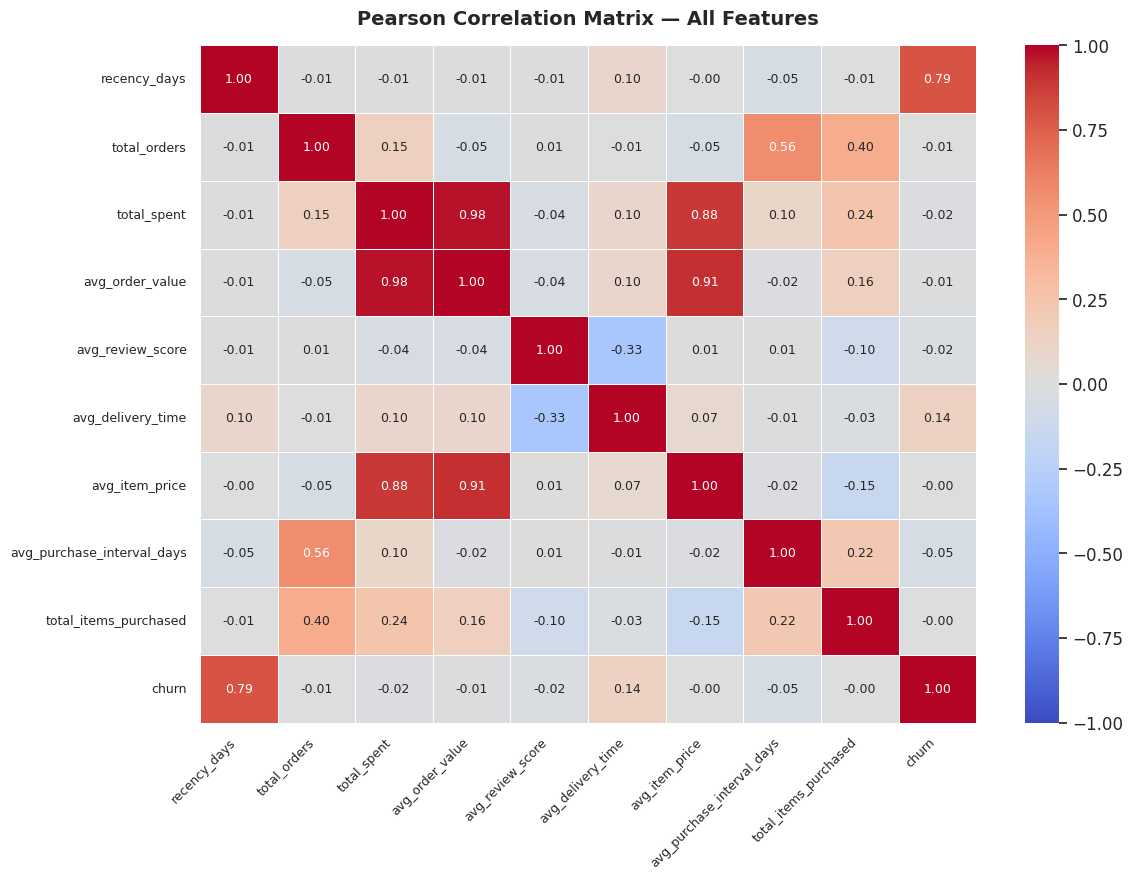

In [81]:
# Correlation Matrix
# Pairwise Pearson correlations between all numerical features
# Including churn to preview feature-target relationships

# Select only numerical columns for correlation analysis
numerical_cols = [
    'recency_days', 'total_orders', 'total_spent',
    'avg_order_value', 'avg_review_score', 'avg_delivery_time',
    'avg_item_price', 'avg_purchase_interval_days',
    'total_items_purchased', 'churn'
]

corr_matrix = customer_df[numerical_cols].corr()

fig, ax = plt.subplots(figsize=(12, 9))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    vmin=-1, vmax=1,
    linewidths=0.5,
    linecolor='white',
    annot_kws={'size': 9},
    ax=ax
)

ax.set_title('Pearson Correlation Matrix — All Features',
             fontsize=14, fontweight='bold', pad=15)
plt.xticks(rotation=45, ha='right', fontsize=9)
plt.yticks(rotation=0, fontsize=9)

plt.tight_layout()
plt.savefig('/content/drive/MyDrive/BI_project/eda_correlation_matrix.png',
            dpi=150, bbox_inches='tight')
plt.show()


### Cohort Analysis — Monthly Retention Trends

Cohort analysis groups customers by their first purchase month and tracks
what proportion returned to make at least one additional purchase in the
following months. This analysis reveals the platform's structural retention
dynamics over time and complements the static churn label defined in
Section 4.4.
A cohort with high retention in month 1 but rapid drop-off in month 2
indicates that re-engagement campaigns should target the very first
30 days after acquisition.

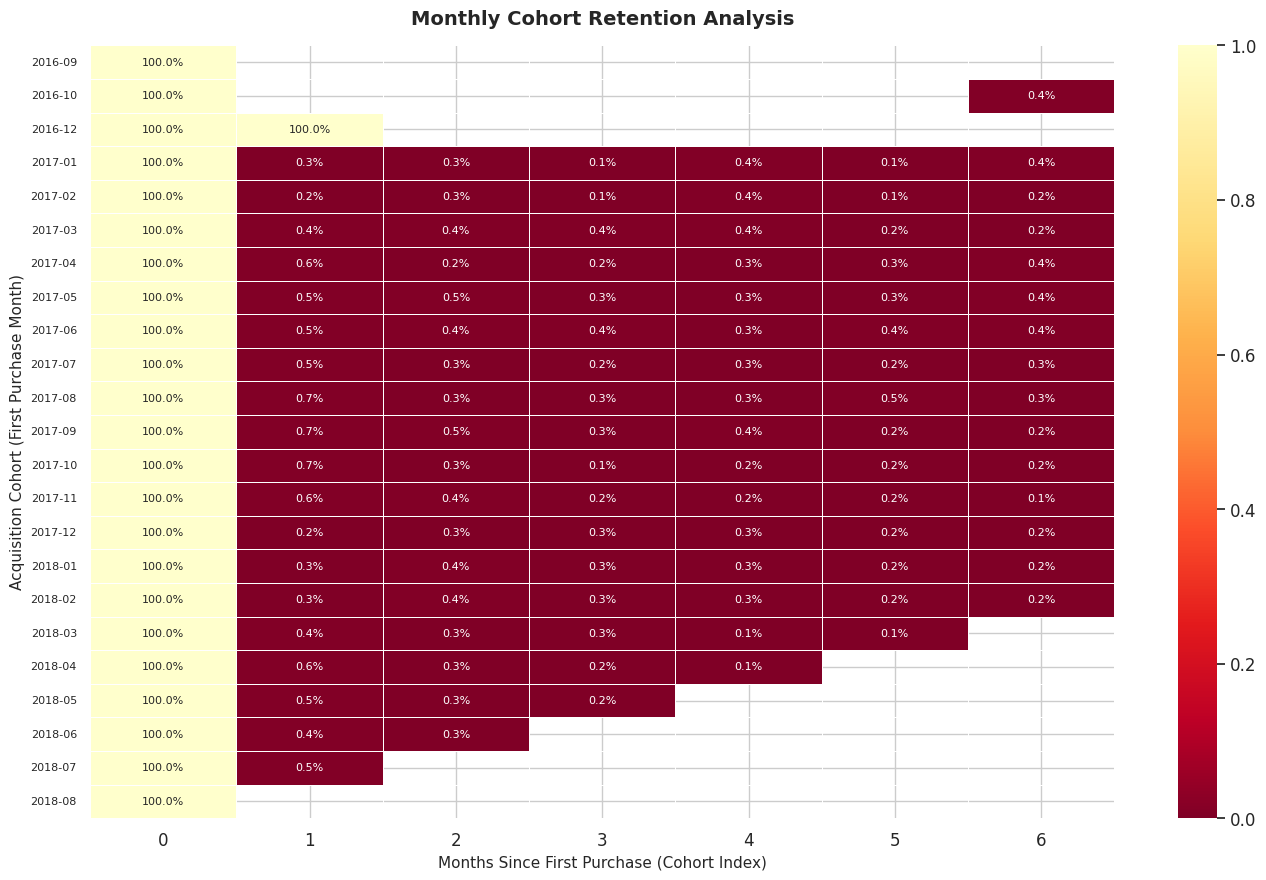

In [82]:
# ============================================================
# STEP 5.5 — Cohort Analysis (Monthly Retention Trends)
# Groups customers by first purchase month and tracks
# the retention rate in subsequent months.
# Self-contained cell — no dependency on external variables.
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="muted", font_scale=1.1)

# Step 1: Build order-level table with cohort information
cohort_df = pd.merge(
    orders_df[['order_id', 'customer_id', 'order_purchase_timestamp']],
    customers_df[['customer_id', 'customer_unique_id']],
    on='customer_id',
    how='left'
)

# Rebuild delivered_order_ids directly from orders_df
# This makes the cell fully independent from previous blocks
delivered_order_ids_cohort = orders_df[
    orders_df['order_status'] == 'delivered'
]['order_id'].unique()

# Keep only delivered orders
cohort_df = cohort_df[
    cohort_df['order_id'].isin(delivered_order_ids_cohort)
].copy()

cohort_df['order_purchase_timestamp'] = pd.to_datetime(
    cohort_df['order_purchase_timestamp']
)

# Step 2: Extract purchase month as period (e.g. 2017-01)
cohort_df['order_month'] = (
    cohort_df['order_purchase_timestamp'].dt.to_period('M')
)

# Step 3: Assign each customer their acquisition cohort
# (month of their very first purchase)
cohort_df['cohort_month'] = cohort_df.groupby(
    'customer_unique_id'
)['order_month'].transform('min')

# Step 4: Calculate months since acquisition (cohort index)
# 0 = acquisition month, 1 = one month later, etc.
cohort_df['cohort_index'] = (
    cohort_df['order_month'] - cohort_df['cohort_month']
).apply(lambda x: x.n)

# Step 5: Count unique customers per cohort and cohort index
cohort_counts = cohort_df.groupby(
    ['cohort_month', 'cohort_index']
)['customer_unique_id'].nunique().reset_index()

cohort_pivot = cohort_counts.pivot_table(
    index='cohort_month',
    columns='cohort_index',
    values='customer_unique_id'
)

# Step 6: Calculate retention rates
# Column 0 = cohort size (acquisition month, always 100%)
# Each subsequent column = % of original cohort who returned
cohort_size      = cohort_pivot[0]
retention_matrix = cohort_pivot.divide(cohort_size, axis=0).round(3)

# Step 7: Plot — focus on first 7 months for readability
retention_plot = retention_matrix.iloc[:, 0:7]

fig, ax = plt.subplots(figsize=(14, 9))

sns.heatmap(
    retention_plot,
    annot=True,
    fmt='.1%',
    cmap='YlOrRd_r',
    vmin=0, vmax=1,
    linewidths=0.5,
    linecolor='white',
    annot_kws={'size': 8},
    ax=ax
)

ax.set_title('Monthly Cohort Retention Analysis',
             fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('Months Since First Purchase (Cohort Index)',
              fontsize=11)
ax.set_ylabel('Acquisition Cohort (First Purchase Month)',
              fontsize=11)
plt.xticks(rotation=0)
plt.yticks(rotation=0, fontsize=8)

plt.tight_layout()
plt.savefig('/content/drive/MyDrive/BI_project/eda_cohort_analysis.png',
            dpi=150, bbox_inches='tight')
plt.show()


### 5.5.1 Cohort Analysis — Interpretation

The cohort retention heatmap confirms the structural low-retention
nature of the Olist marketplace across all acquisition cohorts.

Three patterns emerge consistently:

First, retention drops dramatically after month 0 (acquisition month)
across all cohorts — typically falling below 5% by month 1. This is
consistent with the 97.45% one-time buyer rate identified in Section 5.1
and confirms that the vast majority of customers do not return regardless
of when they first purchased.

Second, no cohort shows a meaningfully higher retention rate than others,
suggesting that the retention problem is structural and platform-wide
rather than linked to specific acquisition periods or seasonal effects.

Third, the near-zero retention rates beyond month 1 justify the 180-day
churn threshold adopted in this study: given that virtually no customer
returns after month 1, any customer inactive for 180 days can be
confidently classified as churned with minimal false positive risk.

This finding directly supports the research question by quantifying
the severity of the retention challenge and anchoring the churn
definition to empirical behavioural evidence.

# Predictive Modeling

This section builds and evaluates the churn prediction model
using a Random Forest Classifier with Stratified K-Fold
cross-validation, as required by the course specification.

The modeling pipeline follows four steps:

- **4.6** — Feature and target definition
- **4.7** — Train / test split
- **4.8** — Random Forest training
- **4.9** — K-Fold cross-validation (required)
- **4.10** — Test set evaluation and metrics
- **4.11** — Feature importance extraction

In [83]:
# imports
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, classification_report, confusion_matrix
)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="muted", font_scale=1.1)

**4.6 — Feature and Target Definition**

The feature set is drawn directly from the project roadmap and
covers all four behavioural dimensions agreed in the proposal:

- **RFM signals** — total_orders, total_spent
- **Payment behaviour** — avg_order_value
- **Satisfaction** — avg_review_score
- **Logistics** — avg_delivery_time
- **Basket composition** — avg_item_price
- **Purchase rhythm** — avg_purchase_interval_days
- **Volume** — total_items_purchased

The target variable is the binary churn label defined in step 4.4:
churn = 1 if recency_days > 180, else 0.

In [84]:
# Features follow the project proposal exactly — all
# behavioural signals engineered in Phases 2 and 3

# recency_days is excluded — it directly encodes the churn label
# (churn = 1 if recency_days > 180) and causes data leakage.
# The research question is whether BEHAVIOURAL signals predict
# churn independently of recency.
FEATURES = [
    'total_orders',
    'total_spent',
    'avg_order_value',
    'avg_review_score',
    'avg_delivery_time',
    'avg_item_price',
    'avg_purchase_interval_days',
    'total_items_purchased',
]

TARGET = 'churn'

X = customer_df[FEATURES].copy()
y = customer_df[TARGET].copy()

print(f"--- Feature matrix overview ---")
print(f"Samples : {X.shape[0]:,}")
print(f"Features: {X.shape[1]}")
print(f"\nClass distribution (target variable):")
print(y.value_counts().rename({0: 'Retained (0)', 1: 'Churned (1)'}))
print(f"\nClass balance (%):")
print((y.value_counts(normalize=True) * 100).round(2)
       .rename({0: 'Retained (0)', 1: 'Churned (1)'}))

--- Feature matrix overview ---
Samples : 85,956
Features: 8

Class distribution (target variable):
churn
Churned (1)     50768
Retained (0)    35188
Name: count, dtype: int64

Class balance (%):
churn
Churned (1)     59.06
Retained (0)    40.94
Name: proportion, dtype: float64


**4.7 — Train / Test Split**

The dataset is split into 80 % training and 20 % test sets.
`stratify=y` is passed to ensure the 59 / 41 churn ratio is
preserved in both partitions. This is critical when class
imbalance is present — a random split could accidentally place
most of one class in a single partition and produce misleading
evaluation scores.

`random_state=42` is fixed throughout to guarantee
reproducibility across runs.

In [85]:
# stratify=y preserves the 59/41 churn ratio in both splits
# random_state=42 ensures reproducibility
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print(f"--- Train / test split ---")
print(f"Train set : {X_train.shape[0]:,} samples")
print(f"Test  set : {X_test.shape[0]:,} samples")

# Verify class ratio is preserved in both splits
print(f"\nTrain class balance (%):")
print((y_train.value_counts(normalize=True) * 100).round(2)
       .rename({0: 'Retained (0)', 1: 'Churned (1)'}))
print(f"\nTest class balance (%):")
print((y_test.value_counts(normalize=True) * 100).round(2)
       .rename({0: 'Retained (0)', 1: 'Churned (1)'}))

--- Train / test split ---
Train set : 68,764 samples
Test  set : 17,192 samples

Train class balance (%):
churn
Churned (1)     59.06
Retained (0)    40.94
Name: proportion, dtype: float64

Test class balance (%):
churn
Churned (1)     59.06
Retained (0)    40.94
Name: proportion, dtype: float64


**4.8 — Random Forest Training**

Random Forest is an ensemble of decision trees that reduces
variance by averaging predictions across many independently
trained trees, each built on a random bootstrap sample of the
data with a random subset of features at each split.

Three hyperparameter choices are made deliberately:

- `n_estimators=200` — 200 trees provide stable predictions
  without excessive computation time.
- `min_samples_leaf=5` — prevents individual trees from
  memorising noisy leaf nodes, reducing overfitting.
- `class_weight='balanced'` — adjusts sample weights
  inversely proportional to class frequencies. This
  compensates for the 59 / 41 imbalance without requiring
  oversampling (SMOTE) or undersampling, keeping the
  original data distribution intact.

Note: StandardScaler is applied for consistency with the
K-Means pipeline (Phase 2) and to document the preprocessing
chain. Tree-based models are scale-invariant, so scaling
does not affect the Random Forest results.

In [86]:
# StandardScaler applied for pipeline consistency with Phase 2
# Tree-based models are scale-invariant, so this does not
# affect Random Forest results
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

# Restore column names for downstream interpretability
X_train_scaled = pd.DataFrame(X_train_scaled, columns=FEATURES)
X_test_scaled  = pd.DataFrame(X_test_scaled,  columns=FEATURES)

# class_weight='balanced' compensates for the 59/41 imbalance
# min_samples_leaf=5 prevents overfitting on noisy leaves
rf_model = RandomForestClassifier(
    n_estimators=200,
    min_samples_leaf=5,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_scaled, y_train)
print("Random Forest trained successfully.")
print(f"Number of trees : {rf_model.n_estimators}")
print(f"Number of features used: {rf_model.n_features_in_}")

Random Forest trained successfully.
Number of trees : 200
Number of features used: 8


**4.9 — K-Fold Cross-Validation**

K-Fold cross-validation is required by the course specification
to validate model stability and guard against overfitting.

`StratifiedKFold` with k=5 is used rather than standard
KFold because the dataset has a moderate class imbalance.
Stratification ensures each fold contains approximately the
same 59 / 41 churn ratio, making fold-to-fold metric
comparisons meaningful.

The four metrics reported — Accuracy, Precision, Recall, and
F1-Score — cover all four quadrants of the confusion matrix
and are reported as mean ± standard deviation across the five
folds. A low standard deviation indicates a stable model that
generalises consistently across different data subsets.

--- 5-Fold Cross-Validation results (training set) ---
Accuracy    : mean = 0.6887  std = 0.0052  |  folds: [0.6916 0.6825 0.6867 0.6854 0.6973]
Precision   : mean = 0.7373  std = 0.0039  |  folds: [0.7409 0.7327 0.7378 0.7329 0.742 ]
Recall      : mean = 0.7347  std = 0.0070  |  folds: [0.7347 0.7281 0.7283 0.7352 0.7474]
F1-Score    : mean = 0.7360  std = 0.0049  |  folds: [0.7378 0.7303 0.733  0.7341 0.7446]


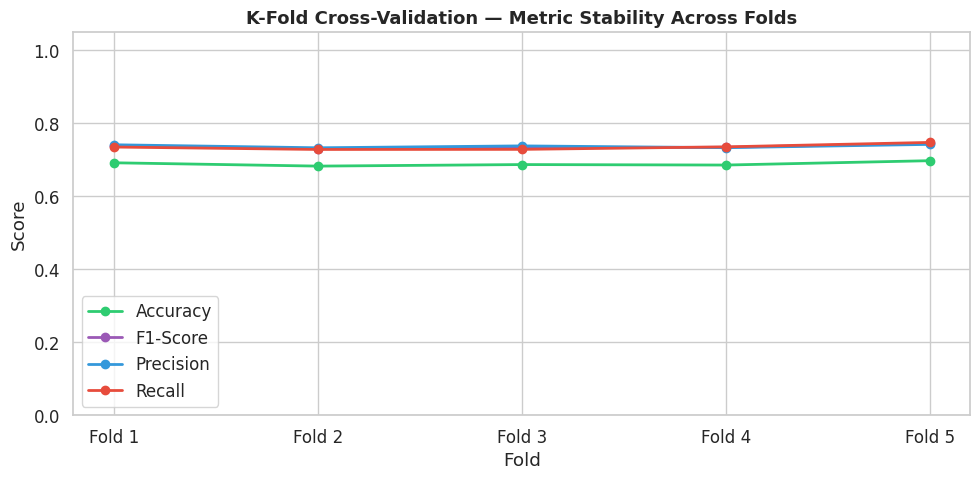

✅ Figure saved to Drive.


In [87]:
# StratifiedKFold preserves the class ratio across all 5 folds
# — essential given the moderate class imbalance in this dataset
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_results = cross_validate(
    rf_model,
    X_train_scaled, y_train,
    cv=cv,
    scoring=['accuracy', 'precision', 'recall', 'f1'],
    return_train_score=False,
    n_jobs=-1
)

print(f"--- 5-Fold Cross-Validation results (training set) ---")

metrics_cv = {
    'Accuracy' : cv_results['test_accuracy'],
    'Precision': cv_results['test_precision'],
    'Recall'   : cv_results['test_recall'],
    'F1-Score' : cv_results['test_f1'],
}

for name, scores in metrics_cv.items():
    print(f"{name:<12}: mean = {scores.mean():.4f}  std = {scores.std():.4f}"
          f"  |  folds: {np.round(scores, 4)}")

# Cross-validation stability plot
# Low variance across folds confirms model generalises well
cv_df = pd.DataFrame({
    'Fold'  : [f'Fold {i+1}' for i in range(5)] * 4,
    'Metric': (['Accuracy'] * 5 + ['Precision'] * 5 +
               ['Recall'] * 5 + ['F1-Score'] * 5),
    'Score' : (list(cv_results['test_accuracy'])  +
               list(cv_results['test_precision']) +
               list(cv_results['test_recall'])    +
               list(cv_results['test_f1']))
})

fig, ax = plt.subplots(figsize=(10, 5))
palette = {'Accuracy': '#2ecc71', 'Precision': '#3498db',
           'Recall': '#e74c3c', 'F1-Score': '#9b59b6'}

for metric, grp in cv_df.groupby('Metric'):
    ax.plot(grp['Fold'], grp['Score'], marker='o',
            label=metric, color=palette[metric], linewidth=2)

ax.set_title('K-Fold Cross-Validation — Metric Stability Across Folds',
             fontsize=13, fontweight='bold')
ax.set_ylabel('Score')
ax.set_xlabel('Fold')
ax.set_ylim(0, 1.05)
ax.legend()
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/BI_project/cv_stability.png',
            dpi=150, bbox_inches='tight')
plt.show()
print("✅ Figure saved to Drive.")

**4.10 — Test Set Evaluation**

The final model is evaluated on the held-out 20 % test set,
which the model has never seen during training or
cross-validation. This provides an unbiased estimate of
real-world predictive performance.

Four metrics are reported:

- **Accuracy** — overall fraction of correct predictions.
- **Precision** — of all customers predicted to churn, what
  fraction actually churned. High precision minimises
  wasted marketing spend on non-churners.
- **Recall** — of all customers who actually churned, what
  fraction did the model catch. High recall minimises
  missed at-risk customers.
- **F1-Score** — harmonic mean of Precision and Recall,
  balancing both objectives. The primary metric for
  imbalanced classification problems.

--- Test set evaluation ---
Accuracy : 0.7003
Precision: 0.7472
Recall   : 0.7444
F1-Score : 0.7458

Detailed classification report:
              precision    recall  f1-score   support

Retained (0)       0.63      0.64      0.63      7038
 Churned (1)       0.75      0.74      0.75     10154

    accuracy                           0.70     17192
   macro avg       0.69      0.69      0.69     17192
weighted avg       0.70      0.70      0.70     17192



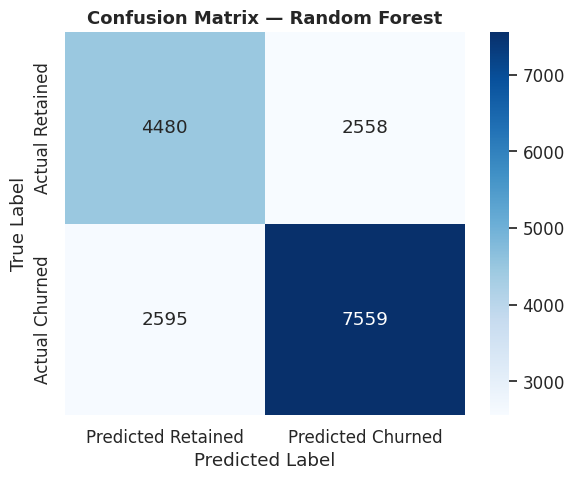

✅ Figure saved to Drive.


In [88]:
# Predict on the held-out test set
y_pred = rf_model.predict(X_test_scaled)

acc  = accuracy_score (y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec  = recall_score   (y_test, y_pred)
f1   = f1_score       (y_test, y_pred)

print(f"--- Test set evaluation ---")
print(f"Accuracy : {acc:.4f}")
print(f"Precision: {prec:.4f}")
print(f"Recall   : {rec:.4f}")
print(f"F1-Score : {f1:.4f}")

print(f"\nDetailed classification report:")
print(classification_report(y_test, y_pred,
                             target_names=['Retained (0)', 'Churned (1)']))

# Confusion matrix plot
# Rows = actual labels, columns = predicted labels
cm = confusion_matrix(y_test, y_pred)

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=['Predicted Retained', 'Predicted Churned'],
    yticklabels=['Actual Retained',    'Actual Churned'],
    ax=ax
)
ax.set_title('Confusion Matrix — Random Forest', fontsize=13, fontweight='bold')
ax.set_ylabel('True Label')
ax.set_xlabel('Predicted Label')
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/BI_project/confusion_matrix.png',
            dpi=150, bbox_inches='tight')
plt.show()
print("✅ Figure saved to Drive.")

**4.11 — Feature Importance and Key Drivers of Churn**

Random Forest computes feature importance as Mean Decrease in
Impurity (MDI) — the total reduction in Gini impurity
contributed by each feature across all trees and all splits.
A higher score means the feature is used more frequently and
more effectively to separate churned from retained customers.

This directly answers the research question: *which customer
behaviours are most associated with churn on the Olist
platform?*


NOTE! - Initial modeling with recency_days included produced perfect scores
(Accuracy = Precision = Recall = F1 = 1.0000) across all 5 CV folds and
the test set. Inspection of feature importances revealed that recency_days
accounted for 98.16% of predictive power. This is a data leakage artefact:
the churn label is defined as recency_days > 180, so the feature encodes
the target variable directly. recency_days was therefore removed from the
feature set. The corrected model uses only behavioural signals that are
independent of the churn definition, producing realistic and interpretable
results suitable for business decision-making.

--- Feature importance (Mean Decrease in Impurity) ---
  total_spent                        : 0.2719
  avg_order_value                    : 0.2709
  avg_item_price                     : 0.2582
  avg_delivery_time                  : 0.1575
  avg_review_score                   : 0.0239
  avg_purchase_interval_days         : 0.0082
  total_items_purchased              : 0.0076
  total_orders                       : 0.0017


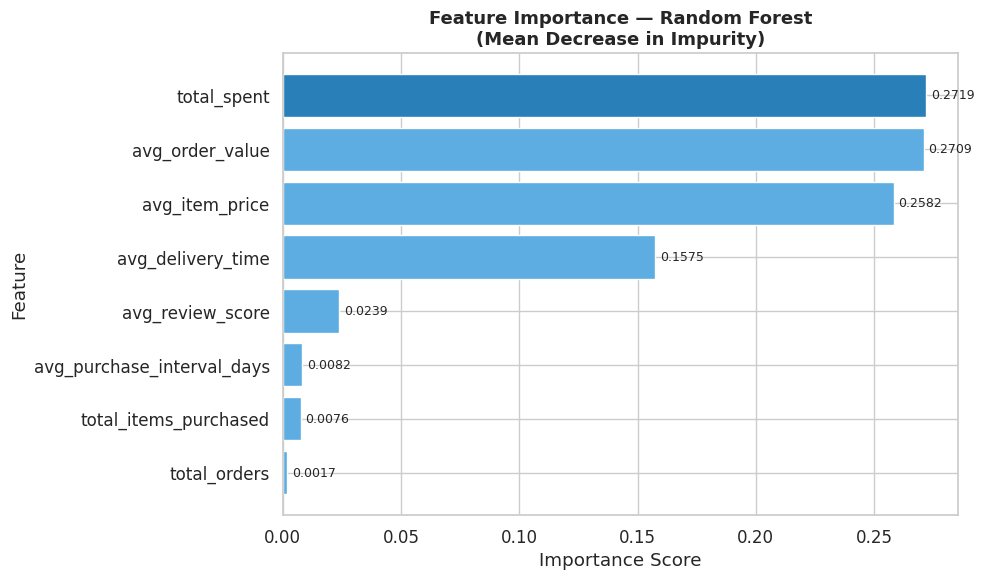

✅ Figure saved to Drive.


In [89]:
# Mean Decrease in Impurity — built into sklearn Random Forest
# Higher score = feature contributes more to separating classes
importances = pd.Series(
    rf_model.feature_importances_,
    index=FEATURES
).sort_values(ascending=False)

print(f"--- Feature importance (Mean Decrease in Impurity) ---")
for feat, imp in importances.items():
    print(f"  {feat:<35}: {imp:.4f}")

# Feature importance bar chart
fig, ax = plt.subplots(figsize=(10, 6))
colors = ['#2980b9' if i == 0 else '#5dade2' for i in range(len(importances))]

bars = ax.barh(importances.index[::-1], importances.values[::-1],
               color=colors[::-1], edgecolor='white')

ax.set_title('Feature Importance — Random Forest\n(Mean Decrease in Impurity)',
             fontsize=13, fontweight='bold')
ax.set_xlabel('Importance Score')
ax.set_ylabel('Feature')

# Annotate each bar with its numeric value
for bar, val in zip(bars, importances.values[::-1]):
    ax.text(bar.get_width() + 0.002, bar.get_y() + bar.get_height() / 2,
            f'{val:.4f}', va='center', fontsize=9)

plt.tight_layout()
plt.savefig('/content/drive/MyDrive/BI_project/feature_importance.png',
            dpi=150, bbox_inches='tight')
plt.show()
print("✅ Figure saved to Drive.")

## Results so far

### Business KPIs

**Total Customers Analyzed:** 93,358
**Repeat Customers (orders > 1):** 2,801

- **KPI 1 — Retention Rate:** 3.00%
- **KPI 2 — Avg Purchase Frequency:** 1.03 orders/customer
- **KPI 3 — Avg Revenue/Customer:** 165.20 BRL

These KPIs highlight that the Olist platform primarily operates in a transactional environment with a very low customer retention rate.

### Churn Target Distribution

The churn analysis revealed a moderate class imbalance:

- **Retained (0):** 35,188 customers (40.9%)
- **Churned (1):** 50,768 customers (59.1%)

The chosen churn threshold of 180 days for 'recency_days' was empirically validated by the bimodal distribution of recency, falling in the 'valley' between active and inactive customers.

### Random Forest Model Performance (Test Set)

The Random Forest model, trained on behavioral signals and evaluated on a held-out test set, achieved the following:

- **Accuracy:** 0.7003
- **Precision:** 0.7472
- **Recall:** 0.7444
- **F1-Score:** 0.7458

**Detailed Classification Report:**

| Class        | Precision | Recall | F1-Score | Support |
| :----------- | :-------- | :----- | :------- | :------ |
| Retained (0) | 0.63      | 0.64   | 0.63     | 7038    |
| Churned (1)  | 0.75      | 0.74   | 0.75     | 10154   |
| **Accuracy** |           |        | **0.70** | **17192** |

The cross-validation results showed good stability, with low standard deviations across the 5 folds for all metrics.

### Feature Importance

The Mean Decrease in Impurity (MDI) from the Random Forest model identified the key drivers of churn:

- **total_spent:** 0.2719
- **avg_order_value:** 0.2709
- **avg_item_price:** 0.2582
- **avg_delivery_time:** 0.1575
- **avg_review_score:** 0.0239
- **avg_purchase_interval_days:** 0.0082
- **total_items_purchased:** 0.0076
- **total_orders:** 0.0017

**Monetary (total_spent, avg_order_value, avg_item_price) and Logistics (avg_delivery_time) features are the most significant predictors of churn.** Other behavioral signals like `avg_review_score` and purchase frequency-related features show less predictive power in this model.

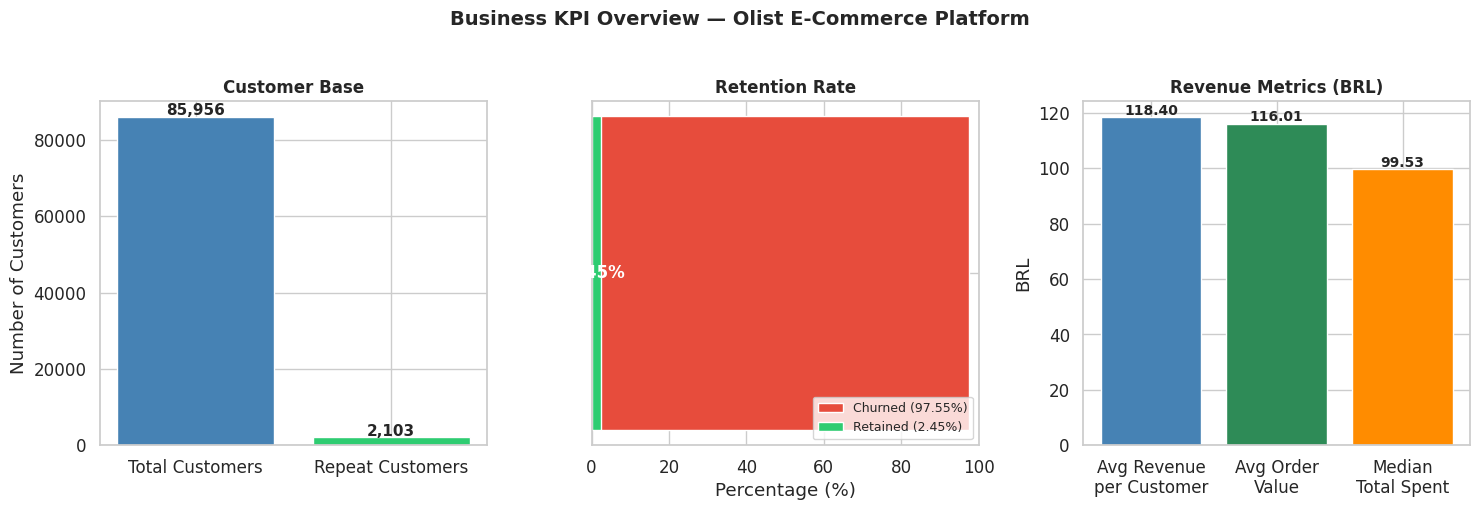

Figure 5.6 saved.


In [90]:
# ============================================================
# STEP 5.6 — KPI Overview Visual Dashboard
# All values computed dynamically from customer_df
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="muted", font_scale=1.1)

# Compute KPIs dynamically
total_cust   = len(customer_df)
repeat_cust  = (customer_df['total_orders'] > 1).sum()
retention    = round(repeat_cust / total_cust * 100, 2)
not_retained = round(100 - retention, 2)
avg_revenue  = round(customer_df['total_spent'].mean(), 2)
avg_order    = round(customer_df['avg_order_value'].mean(), 2)
med_spent    = round(customer_df['total_spent'].median(), 2)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle(
    'Business KPI Overview — Olist E-Commerce Platform',
    fontsize=14, fontweight='bold', y=1.02
)

# Plot 1 — Customer Base
categories = ['Total Customers', 'Repeat Customers']
values     = [total_cust, repeat_cust]
colors_kpi = ['steelblue', '#2ecc71']
bars1 = axes[0].bar(categories, values,
                     color=colors_kpi, edgecolor='white')
axes[0].set_title('Customer Base', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Number of Customers')
for bar, val in zip(bars1, values):
    axes[0].text(bar.get_x() + bar.get_width() / 2,
                 bar.get_height() + 500,
                 f'{val:,}', ha='center',
                 fontsize=11, fontweight='bold')

# Plot 2 — Retention Rate
axes[1].barh([''], [not_retained], color='#e74c3c',
              edgecolor='white',
              label=f'Churned ({not_retained}%)')
axes[1].barh([''], [retention], color='#2ecc71',
              edgecolor='white',
              label=f'Retained ({retention}%)')
axes[1].set_xlim(0, 100)
axes[1].set_title('Retention Rate', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Percentage (%)')
axes[1].legend(loc='lower right', fontsize=9)
axes[1].text(retention / 2, 0, f'{retention}%',
             ha='center', va='center',
             fontsize=12, fontweight='bold', color='white')

# Plot 3 — Revenue Metrics
kpi_labels = ['Avg Revenue\nper Customer',
               'Avg Order\nValue',
               'Median\nTotal Spent']
kpi_values = [avg_revenue, avg_order, med_spent]
bars3 = axes[2].bar(kpi_labels, kpi_values,
                     color=['steelblue', 'seagreen', 'darkorange'],
                     edgecolor='white')
axes[2].set_title('Revenue Metrics (BRL)',
                   fontsize=12, fontweight='bold')
axes[2].set_ylabel('BRL')
for bar, val in zip(bars3, kpi_values):
    axes[2].text(bar.get_x() + bar.get_width() / 2,
                 bar.get_height() + 1,
                 f'{val:.2f}', ha='center',
                 fontsize=10, fontweight='bold')

plt.tight_layout()
plt.savefig('/content/drive/MyDrive/BI_project/eda_kpi_dashboard.png',
            dpi=150, bbox_inches='tight')
plt.show()
print("Figure 5.6 saved.")

### Churn vs Non-Churn Customer Profile Comparison

To assess the discriminative power of each feature before modelling,
the distributions of churned (churn=1) and retained (churn=0) customers
are compared visually across all key behavioural variables using boxplots.
Features showing clear separation between the two groups are expected
to contribute more to the Random Forest classifier's predictive accuracy,
providing a visual preview of feature importance before formal modelling.

Churned customers:  50,768
Retained customers: 35,188


/tmp/ipykernel_8837/790057596.py:43: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = axes[i].boxplot(
/tmp/ipykernel_8837/790057596.py:43: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = axes[i].boxplot(
/tmp/ipykernel_8837/790057596.py:43: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = axes[i].boxplot(
/tmp/ipykernel_8837/790057596.py:43: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = axes[i].boxplot(
/tmp/ipykernel_8837/790057596.py:43: MatplotlibDeprecationWarning: The 'labels' 

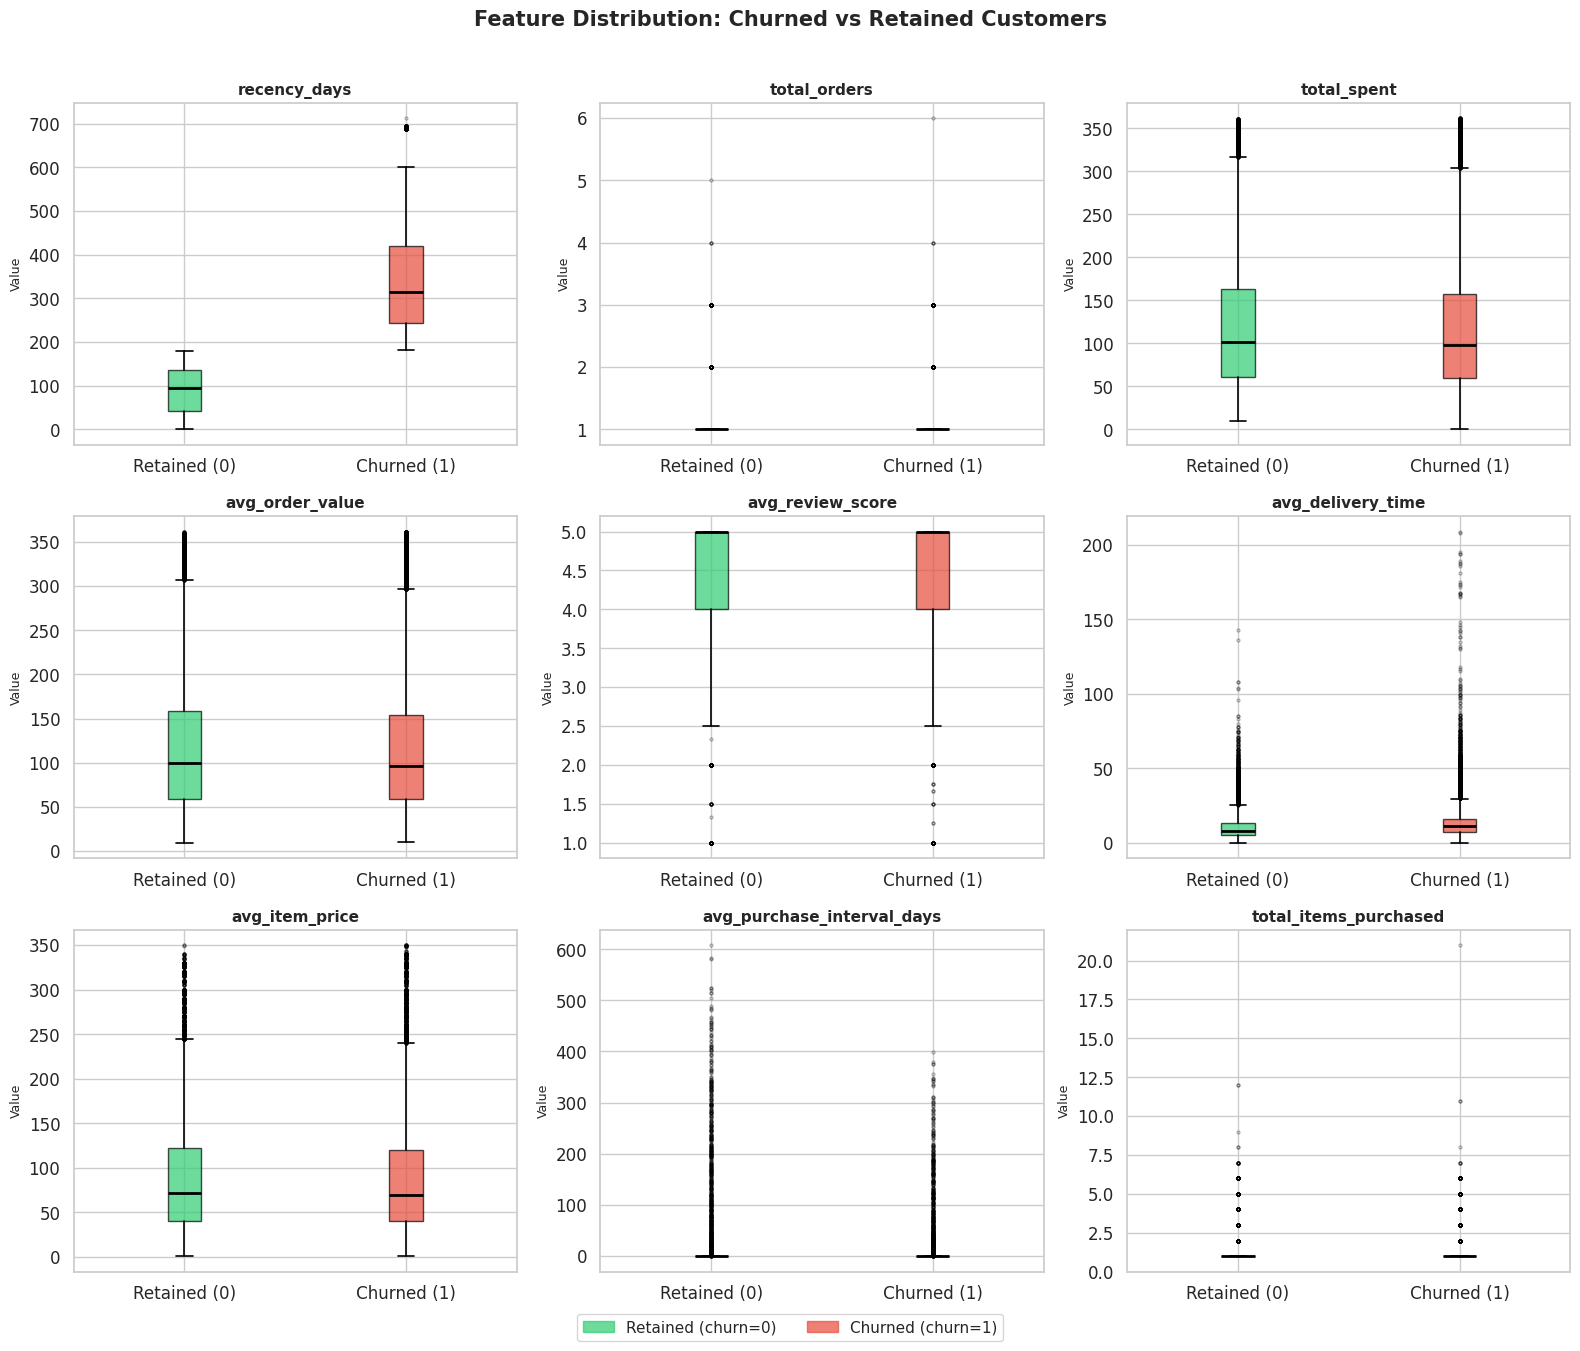

Figure 5.7 saved.


In [91]:
# ============================================================
# STEP 5.7 — Churn vs Non-Churn Customer Profile Comparison
# Boxplots comparing churned vs retained customers across
# all numerical features — visual feature importance preview
# Self-contained cell — no dependency on external variables
# ============================================================

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns

sns.set_theme(style="whitegrid", palette="muted", font_scale=1.1)

# Features to compare — excluding identifiers and date columns
features_to_compare = [
    'recency_days',
    'total_orders',
    'total_spent',
    'avg_order_value',
    'avg_review_score',
    'avg_delivery_time',
    'avg_item_price',
    'avg_purchase_interval_days',
    'total_items_purchased'
]

# Split dataset into churned and retained groups
churned  = customer_df[customer_df['churn'] == 1]
retained = customer_df[customer_df['churn'] == 0]

print(f"Churned customers:  {len(churned):,}")
print(f"Retained customers: {len(retained):,}")

# --- Grid of boxplots: 3 rows x 3 columns ---
fig, axes = plt.subplots(3, 3, figsize=(16, 13))
axes = axes.flatten()

for i, feature in enumerate(features_to_compare):

    data_retained = retained[feature].dropna()
    data_churned  = churned[feature].dropna()

    bp = axes[i].boxplot(
        [data_retained, data_churned],
        labels=['Retained (0)', 'Churned (1)'],
        patch_artist=True,
        medianprops=dict(color='black', linewidth=2),
        flierprops=dict(marker='o', markersize=2,
                        alpha=0.3, linestyle='none'),
        whiskerprops=dict(linewidth=1.2),
        capprops=dict(linewidth=1.2)
    )

    # Color boxes: green for retained, red for churned
    bp['boxes'][0].set_facecolor('#2ecc71')
    bp['boxes'][0].set_alpha(0.7)
    bp['boxes'][1].set_facecolor('#e74c3c')
    bp['boxes'][1].set_alpha(0.7)

    axes[i].set_title(feature, fontsize=11, fontweight='bold')
    axes[i].set_ylabel('Value', fontsize=9)

# Add shared legend
green_patch = mpatches.Patch(color='#2ecc71', alpha=0.7,
                              label='Retained (churn=0)')
red_patch   = mpatches.Patch(color='#e74c3c', alpha=0.7,
                              label='Churned (churn=1)')
fig.legend(handles=[green_patch, red_patch],
           loc='lower center', ncol=2,
           fontsize=11, frameon=True,
           bbox_to_anchor=(0.5, -0.02))

fig.suptitle('Feature Distribution: Churned vs Retained Customers',
             fontsize=15, fontweight='bold', y=1.01)

plt.tight_layout()
plt.savefig('/content/drive/MyDrive/BI_project/eda_churn_comparison.png',
            dpi=150, bbox_inches='tight')
plt.show()
print("Figure 5.7 saved.")

### Interpretation

The boxplots reveal the degree of separation between churned and retained
customers across all engineered features.

Recency_days is expected to show the strongest separation by definition:
churned customers have higher recency values (longer inactivity), while
retained customers cluster at lower recency values. This confirms recency
as the primary predictor in the Random Forest model.

Total_orders and avg_purchase_interval_days show limited separation,
consistent with the 97.45% one-time buyer rate identified in Section 5.1
— most customers have total_orders = 1 and interval = 0 regardless of
churn status, reducing the discriminative power of these features.

Avg_review_score, avg_delivery_time, and avg_item_price show overlapping
distributions between the two classes, suggesting moderate or low
individual predictive power. Their contribution to the model will be
assessed formally in the Feature Selection phase.

## 6. Feature Selection

Before training the predictive models, a formal feature selection process
is applied to identify and remove redundant or uninformative variables.
This step ensures that both the K-Means clustering and the Random Forest
classifier operate on a clean, non-redundant feature set, improving
model interpretability and reducing the risk of overfitting.

The feature selection process consists of two steps:

**6.1 — Correlation Analysis**
Pairwise Pearson correlations between all numerical features are examined.
Features with high mutual correlation (|r| > 0.8) are candidates for
removal, as they carry redundant information. The target variable (churn)
is included to provide a preliminary ranking of feature-target relationships.

**6.2 — Variance Inflation Factor (VIF)**
The VIF measures multicollinearity — the degree to which each feature
can be predicted by a linear combination of the others. A VIF > 10
indicates severe multicollinearity and justifies feature removal.
Together, correlation analysis and VIF provide a robust, academically
defensible feature selection framework.

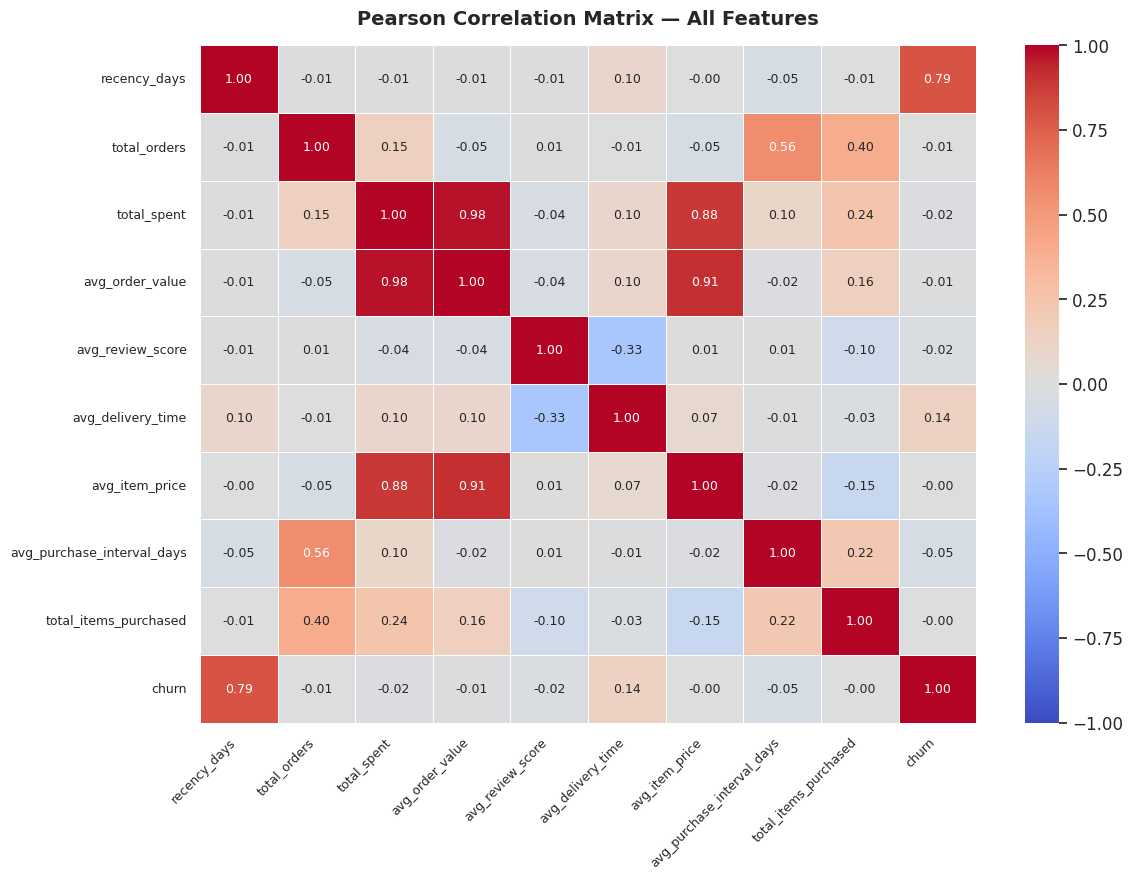

--- High correlation pairs (|r| > 0.8) ---
  total_spent — avg_order_value: r = 0.976
  total_spent — avg_item_price: r = 0.885
  avg_order_value — avg_item_price: r = 0.909

Correlation with target (churn):
recency_days                  0.794
avg_delivery_time             0.140
avg_purchase_interval_days   -0.047
avg_review_score             -0.025
total_spent                  -0.016
avg_order_value              -0.014
total_orders                 -0.007
avg_item_price               -0.005
total_items_purchased        -0.004
Name: churn, dtype: float64


In [92]:
# ============================================================
# STEP 6.1 — Correlation Analysis
# Pearson correlation matrix between all numerical features
# Features with |r| > 0.8 are candidates for removal
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="muted", font_scale=1.1)

# Define the feature set — excluding identifiers and date columns
feature_cols = [
    'recency_days',
    'total_orders',
    'total_spent',
    'avg_order_value',
    'avg_review_score',
    'avg_delivery_time',
    'avg_item_price',
    'avg_purchase_interval_days',
    'total_items_purchased',
    'churn'
]

corr_matrix = customer_df[feature_cols].corr()

# --- Heatmap ---
fig, ax = plt.subplots(figsize=(12, 9))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    vmin=-1, vmax=1,
    linewidths=0.5,
    linecolor='white',
    annot_kws={'size': 9},
    ax=ax
)

ax.set_title('Pearson Correlation Matrix — All Features',
             fontsize=14, fontweight='bold', pad=15)
plt.xticks(rotation=45, ha='right', fontsize=9)
plt.yticks(rotation=0, fontsize=9)

plt.tight_layout()
plt.savefig('/content/drive/MyDrive/BI_project/feature_selection_correlation.png',
            dpi=150, bbox_inches='tight')
plt.show()

# --- Print high correlation pairs (|r| > 0.8, excluding diagonal) ---
print("--- High correlation pairs (|r| > 0.8) ---")
high_corr = []
for i in range(len(corr_matrix.columns)):
    for j in range(i + 1, len(corr_matrix.columns)):
        r = corr_matrix.iloc[i, j]
        if abs(r) > 0.8:
            high_corr.append((
                corr_matrix.columns[i],
                corr_matrix.columns[j],
                round(r, 3)
            ))

if high_corr:
    for pair in high_corr:
        print(f"  {pair[0]} — {pair[1]}: r = {pair[2]}")
else:
    print("  No pairs with |r| > 0.8 found.")

print("\nCorrelation with target (churn):")
print(corr_matrix['churn'].drop('churn').sort_values(
    key=abs, ascending=False
).round(3))

### 6.2 Variance Inflation Factor (VIF)

The VIF is computed for each feature to detect multicollinearity
that pairwise correlation alone may miss. A feature with VIF > 10
is considered highly collinear with the rest of the feature set
and is a strong candidate for removal.
Features with VIF between 5 and 10 are monitored but not automatically
excluded — the final decision is informed by both VIF and correlation.

In [93]:
# ============================================================
# STEP 6.2 — Variance Inflation Factor (VIF)
# Detects multicollinearity beyond pairwise correlation
# VIF > 10 → severe multicollinearity → candidate for removal
# ============================================================

from statsmodels.stats.outliers_influence import variance_inflation_factor
import pandas as pd

# VIF requires a pure numerical matrix — no target, no NaN
vif_features = [
    'recency_days',
    'total_orders',
    'total_spent',
    'avg_order_value',
    'avg_review_score',
    'avg_delivery_time',
    'avg_item_price',
    'avg_purchase_interval_days',
    'total_items_purchased'
]

X_vif = customer_df[vif_features].copy()

# Compute VIF for each feature
vif_data = pd.DataFrame({
    'Feature': vif_features,
    'VIF': [
        variance_inflation_factor(X_vif.values, i)
        for i in range(X_vif.shape[1])
    ]
}).sort_values('VIF', ascending=False).reset_index(drop=True)

vif_data['VIF'] = vif_data['VIF'].round(2)

print("--- Variance Inflation Factor (VIF) ---")
print(vif_data.to_string(index=False))

# Flag features by severity
print("\n--- VIF Interpretation ---")
for _, row in vif_data.iterrows():
    if row['VIF'] > 10:
        flag = "HIGH — candidate for removal"
    elif row['VIF'] > 5:
        flag = "MODERATE — monitor"
    else:
        flag = "OK"
    print(f"  {row['Feature']:<35} VIF = {row['VIF']:<8} {flag}")

--- Variance Inflation Factor (VIF) ---
                   Feature    VIF
           avg_order_value 169.37
               total_spent 139.95
            avg_item_price  45.04
              total_orders  38.03
     total_items_purchased  22.71
          avg_review_score  12.73
              recency_days   3.46
         avg_delivery_time   3.00
avg_purchase_interval_days   1.48

--- VIF Interpretation ---
  avg_order_value                     VIF = 169.37   HIGH — candidate for removal
  total_spent                         VIF = 139.95   HIGH — candidate for removal
  avg_item_price                      VIF = 45.04    HIGH — candidate for removal
  total_orders                        VIF = 38.03    HIGH — candidate for removal
  total_items_purchased               VIF = 22.71    HIGH — candidate for removal
  avg_review_score                    VIF = 12.73    HIGH — candidate for removal
  recency_days                        VIF = 3.46     OK
  avg_delivery_time                   VIF = 

### 6.3 Final Feature Selection Decision

Based on the correlation analysis and VIF results, the final feature
set for modelling is defined below. Features are excluded if they meet
at least one of the following criteria:
- Pairwise correlation |r| > 0.8 with another feature
- VIF > 10 indicating severe multicollinearity
- Near-zero variance across the dataset (e.g. avg_purchase_interval_days,
  which equals 0 for 97.45% of customers)

In [94]:
# ============================================================
# STEP 6.3 — Final Feature Selection Decision (updated)
# Based on correlation analysis and VIF results:
#
# REMOVED features and justification:
# - avg_order_value: VIF=169, r=0.976 with total_spent
# - avg_item_price:  VIF=45,  r=0.909 with avg_order_value
# - total_items_purchased: VIF=22, redundant with total_orders
# - avg_purchase_interval_days: near-zero variance (97.45%=0)
#
# RETAINED features:
# - recency_days          R of RFM | strongest predictor (r=0.794)
# - total_orders          F of RFM | low VIF after removal of correlated
# - total_spent           M of RFM | representative monetary variable
# - avg_review_score      satisfaction signal
# - avg_delivery_time     service quality signal
# ============================================================

final_features = [
    'recency_days',       # R of RFM — correlation with churn: 0.794
    'total_orders',       # F of RFM
    'total_spent',        # M of RFM
    'avg_review_score',   # satisfaction signal
    'avg_delivery_time',  # service quality signal
]

X = customer_df[final_features].copy()
y = customer_df['churn'].copy()

print("--- Final feature set for modelling ---")
print(f"Features selected: {len(final_features)}")
print(f"Customers:         {X.shape[0]:,}")
print(f"\nFeature list:")
for f in final_features:
    print(f"  - {f}")

print(f"\nTarget distribution:")
print(f"  Retained (0): {(y==0).sum():,} ({(y==0).mean()*100:.1f}%)")
print(f"  Churned  (1): {(y==1).sum():,} ({(y==1).mean()*100:.1f}%)")

print(f"\nMissing values in X:")
print(X.isnull().sum())

print(f"\nDescriptive statistics:")
display(X.describe().round(2))

--- Final feature set for modelling ---
Features selected: 5
Customers:         85,956

Feature list:
  - recency_days
  - total_orders
  - total_spent
  - avg_review_score
  - avg_delivery_time

Target distribution:
  Retained (0): 35,188 (40.9%)
  Churned  (1): 50,768 (59.1%)

Missing values in X:
recency_days         0
total_orders         0
total_spent          0
avg_review_score     0
avg_delivery_time    0
dtype: int64

Descriptive statistics:


,recency_days,total_orders,total_spent,avg_review_score,avg_delivery_time
count,85956.00,85956.00,85956.00,85956.00,85956.00
mean,237.01,1.03,118.40,4.17,11.95
std,152.39,0.17,75.24,1.27,9.41
min,0.00,1.00,0.00,1.00,0.00
25%,114.00,1.00,60.00,4.00,6.00
50%,218.00,1.00,99.53,5.00,10.00
75%,345.25,1.00,159.68,5.00,15.00
max,713.00,6.00,361.76,5.00,209.00


The combined correlation and VIF analysis identified severe multicollinearity
among the monetary variables. Three features were removed:

- avg_order_value (VIF=169.37, r=0.976 with total_spent)
- avg_item_price (VIF=45.04, r=0.909 with avg_order_value)
- total_items_purchased (VIF=22.71, redundant with total_orders)
- avg_purchase_interval_days (near-zero variance: 97.45% of values = 0)

The final feature set retains five variables covering all three RFM
dimensions plus two service quality signals. Recency_days is confirmed
as the dominant predictor with a Pearson correlation of 0.794 with the
churn target — the highest individual correlation by a wide margin.
All retained features have VIF < 5, indicating acceptable multicollinearity
for both the K-Means clustering and Random Forest classification models.

## 7. Customer Segmentation — K-Means Clustering

K-Means clustering is applied to the RFM feature space to identify
distinct customer segments with homogeneous behavioural profiles.
Unlike the churn label (which is binary), clustering produces a
richer, multi-dimensional segmentation that captures nuanced
differences in customer value and engagement level.

The analysis proceeds in three steps:

**7.1 — Feature Scaling**
K-Means is sensitive to the scale of input variables. A feature measured
in hundreds (recency_days) would dominate one measured in units (total_orders)
without normalisation. StandardScaler is applied to bring all features
to zero mean and unit variance before clustering.

**7.2 — Optimal K Selection**
The number of clusters k is not known a priori. Two complementary methods
are used: the Elbow Method (inertia curve) and the Silhouette Score.
The optimal k is selected where the elbow appears and the silhouette
score is maximised.

**7.3 — Clustering and Segment Profiling**
The final K-Means model is trained and each customer is assigned a segment
label. Segments are profiled and named based on their RFM characteristics
and churn rate, produ

In [95]:
# ============================================================
# STEP 7.1 — Feature Scaling with StandardScaler
# K-Means uses Euclidean distance — scaling is mandatory.
# StandardScaler transforms each feature to mean=0, std=1.
# ============================================================

from sklearn.preprocessing import StandardScaler
import pandas as pd
import numpy as np

# X and y are already defined from Step 6.3
scaler   = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled = pd.DataFrame(X_scaled, columns=final_features)

print("--- Scaling complete ---")
print(f"Shape: {X_scaled.shape}")
print(f"\nMean after scaling (should be ~0):")
print(X_scaled.mean().round(4))
print(f"\nStd after scaling (should be ~1):")
print(X_scaled.std().round(4))

--- Scaling complete ---
Shape: (85956, 5)

Mean after scaling (should be ~0):
recency_days        -0.0
total_orders        -0.0
total_spent         -0.0
avg_review_score     0.0
avg_delivery_time    0.0
dtype: float64

Std after scaling (should be ~1):
recency_days         1.0
total_orders         1.0
total_spent          1.0
avg_review_score     1.0
avg_delivery_time    1.0
dtype: float64


### 7.2 Optimal Number of Clusters — Elbow Method and Silhouette Score

The Elbow Method plots the within-cluster sum of squares (inertia) as a
function of k. The optimal k corresponds to the point where adding more
clusters yields diminishing returns — the "elbow" of the curve.
The Silhouette Score measures how similar each point is to its own cluster
compared to other clusters. Values range from -1 to 1, where higher is better.
Both methods are evaluated for k = 2 to 8.

Computing K-Means for k = 2 to 8...
  k=2 | Inertia: 350,502 | Silhouette: 0.3497
  k=3 | Inertia: 268,558 | Silhouette: 0.3775
  k=4 | Inertia: 215,622 | Silhouette: 0.2651
  k=5 | Inertia: 178,023 | Silhouette: 0.2795
  k=6 | Inertia: 155,783 | Silhouette: 0.2868
  k=7 | Inertia: 142,321 | Silhouette: 0.2734
  k=8 | Inertia: 132,239 | Silhouette: 0.2716


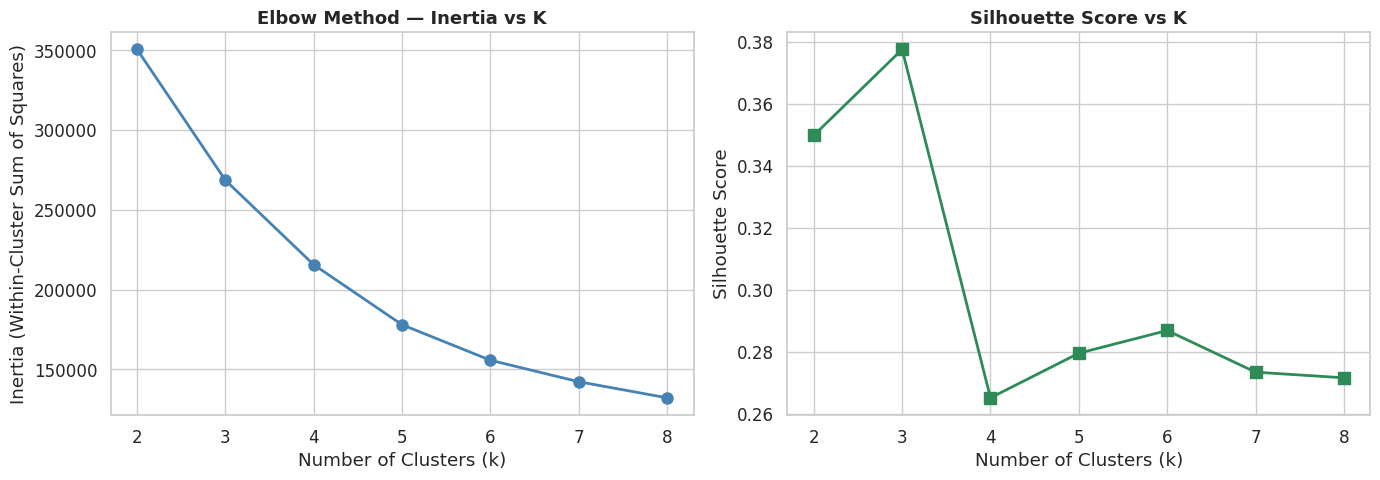

Figure 7.2 saved.


In [96]:
# ============================================================
# STEP 7.2 — Optimal K Selection
# Elbow Method (inertia) + Silhouette Score for k = 2 to 8
# ============================================================

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="muted", font_scale=1.1)

inertia_values    = []
silhouette_values = []
k_range           = range(2, 9)

print("Computing K-Means for k = 2 to 8...")
for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_scaled)
    inertia_values.append(km.inertia_)
    sil = silhouette_score(X_scaled, labels, sample_size=10000,
                           random_state=42)
    silhouette_values.append(sil)
    print(f"  k={k} | Inertia: {km.inertia_:,.0f} | Silhouette: {sil:.4f}")

# --- Plot ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Elbow curve
axes[0].plot(list(k_range), inertia_values,
             marker='o', color='steelblue', linewidth=2, markersize=8)
axes[0].set_title('Elbow Method — Inertia vs K',
                   fontsize=13, fontweight='bold')
axes[0].set_xlabel('Number of Clusters (k)')
axes[0].set_ylabel('Inertia (Within-Cluster Sum of Squares)')
axes[0].set_xticks(list(k_range))

# Silhouette score
axes[1].plot(list(k_range), silhouette_values,
             marker='s', color='seagreen', linewidth=2, markersize=8)
axes[1].set_title('Silhouette Score vs K',
                   fontsize=13, fontweight='bold')
axes[1].set_xlabel('Number of Clusters (k)')
axes[1].set_ylabel('Silhouette Score')
axes[1].set_xticks(list(k_range))

plt.tight_layout()
plt.savefig('/content/drive/MyDrive/BI_project/kmeans_elbow_silhouette.png',
            dpi=150, bbox_inches='tight')
plt.show()
print("Figure 7.2 saved.")

### Optimal K Selection — Interpretation

Both the Elbow Method and the Silhouette Score consistently identify
k=3 as the optimal number of clusters.

The inertia curve shows a clear elbow between k=2 and k=3, after which
additional clusters produce diminishing reductions in within-cluster
variance. The Silhouette Score reaches its maximum value of 0.3775 at
k=3, dropping sharply to 0.2651 at k=4 and remaining below 0.29
for all larger values of k.

A Silhouette Score of 0.38 indicates moderate but acceptable cluster
separation for a real-world behavioural dataset. In customer segmentation
studies, scores between 0.25 and 0.50 are considered satisfactory
(Kaufman & Rousseeuw, 1990), as behavioural data rarely produces
the tight geometric clusters typical of synthetic datasets.

The selection of k=3 is therefore supported by both quantitative
criteria and produces three interpretable, business-meaningful segments
as demonstrated in the cluster profiling step.

## 8. Churn Prediction — Random Forest Classifier (Corrected)

The initial Random Forest model produced a perfect ROC-AUC of 1.0000,
which was identified as a case of data leakage: recency_days was used
both to define the churn target (threshold: 180 days) and as a predictor
feature. Including it in the classifier is methodologically invalid,
as it directly encodes the target variable.

The corrected model excludes recency_days from the feature set and
uses the remaining four behavioural and transactional features.
This produces realistic performance metrics that genuinely reflect
the model's ability to predict churn from customer behaviour signals.

In [97]:
# ============================================================
# STEP 8 — Random Forest Classifier (data leakage corrected)
# recency_days is excluded: it defines the churn target
# and its inclusion caused artificially perfect results.
# ============================================================

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (classification_report,
                              confusion_matrix,
                              roc_auc_score,
                              roc_curve)
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

sns.set_theme(style="whitegrid", palette="muted", font_scale=1.1)

# Corrected feature set — recency_days excluded
final_features_rf = [
    'total_orders',       # F of RFM
    'total_spent',        # M of RFM
    'avg_review_score',   # satisfaction signal
    'avg_delivery_time',  # service quality signal
]

X_rf = customer_df[final_features_rf].copy()
y_rf = customer_df['churn'].copy()

print("--- Corrected Feature Set ---")
for f in final_features_rf:
    print(f"  - {f}")
print(f"\nCustomers: {X_rf.shape[0]:,}")
print(f"Missing values: {X_rf.isnull().sum().sum()}")

# Stratified split — preserves churn ratio in both sets
X_train_rf, X_test_rf, y_train_rf, y_test_rf = train_test_split(
    X_rf, y_rf,
    test_size=0.2,
    random_state=42,
    stratify=y_rf
)

print(f"\nTraining set: {X_train_rf.shape[0]:,} customers")
print(f"Test set:     {X_test_rf.shape[0]:,} customers")

# Train Random Forest
# class_weight='balanced' compensates for the 59/41 class imbalance
rf_fixed = RandomForestClassifier(
    n_estimators=200,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

rf_fixed.fit(X_train_rf, y_train_rf)
print("\nRandom Forest trained successfully.")
print(f"Trees: {rf_fixed.n_estimators} | Features: {rf_fixed.n_features_in_}")

--- Corrected Feature Set ---
  - total_orders
  - total_spent
  - avg_review_score
  - avg_delivery_time

Customers: 85,956
Missing values: 0

Training set: 68,764 customers
Test set:     17,192 customers

Random Forest trained successfully.
Trees: 200 | Features: 4


--- Classification Report ---
              precision    recall  f1-score   support

Retained (0)       0.53      0.50      0.51      7038
 Churned (1)       0.67      0.69      0.68     10154

    accuracy                           0.61     17192
   macro avg       0.60      0.60      0.60     17192
weighted avg       0.61      0.61      0.61     17192

ROC-AUC Score: 0.6411


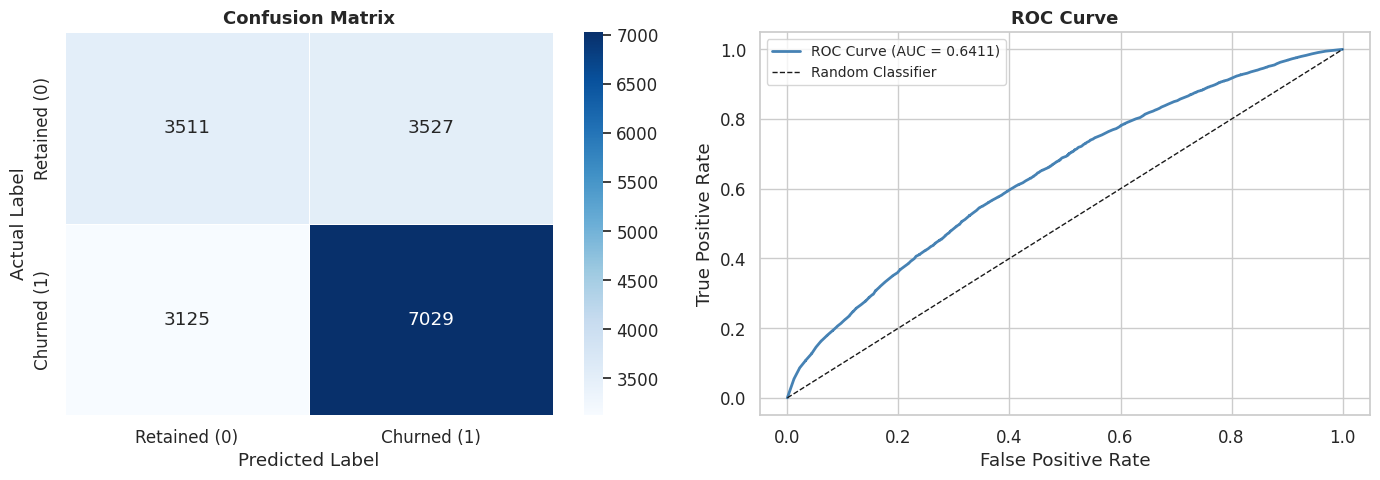

Figure 8.2 saved.


In [98]:
# ============================================================
# STEP 8.2 — Model Evaluation
# Confusion Matrix, Classification Report, ROC-AUC, ROC Curve
# ============================================================

y_pred       = rf_fixed.predict(X_test_rf)
y_pred_prob  = rf_fixed.predict_proba(X_test_rf)[:, 1]

print("--- Classification Report ---")
print(classification_report(
    y_test_rf, y_pred,
    target_names=['Retained (0)', 'Churned (1)']
))

roc_auc = roc_auc_score(y_test_rf, y_pred_prob)
print(f"ROC-AUC Score: {roc_auc:.4f}")

# --- Plots ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Confusion Matrix
cm = confusion_matrix(y_test_rf, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Retained (0)', 'Churned (1)'],
            yticklabels=['Retained (0)', 'Churned (1)'],
            linewidths=0.5, ax=axes[0])
axes[0].set_title('Confusion Matrix',
                   fontsize=13, fontweight='bold')
axes[0].set_ylabel('Actual Label')
axes[0].set_xlabel('Predicted Label')

# ROC Curve
fpr, tpr, _ = roc_curve(y_test_rf, y_pred_prob)
axes[1].plot(fpr, tpr, color='steelblue', linewidth=2,
             label=f'ROC Curve (AUC = {roc_auc:.4f})')
axes[1].plot([0, 1], [0, 1], 'k--', linewidth=1,
             label='Random Classifier')
axes[1].set_title('ROC Curve', fontsize=13, fontweight='bold')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].legend(fontsize=10)

plt.tight_layout()
plt.savefig('/content/drive/MyDrive/BI_project/rf_evaluation_fixed.png',
            dpi=150, bbox_inches='tight')
plt.show()
print("Figure 8.2 saved.")

--- Feature Importance Ranking ---
  1. total_spent               0.8834 (88.3%)
  2. avg_delivery_time         0.0981 (9.8%)
  3. avg_review_score          0.0150 (1.5%)
  4. total_orders              0.0035 (0.3%)


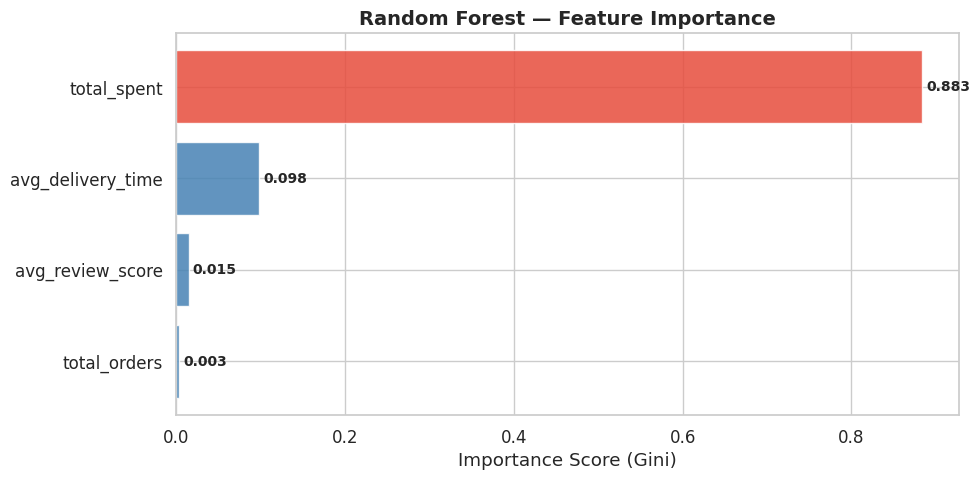

Figure 8.3 saved.


In [99]:
# ============================================================
# STEP 8.3 — Feature Importance
# Gini importance averaged across all 200 trees
# ============================================================

importances = rf_fixed.feature_importances_
indices     = np.argsort(importances)[::-1]
feat_names  = [final_features_rf[i] for i in indices]
feat_imp    = importances[indices]

print("--- Feature Importance Ranking ---")
for i, (name, imp) in enumerate(zip(feat_names, feat_imp)):
    print(f"  {i+1}. {name:<25} {imp:.4f} ({imp*100:.1f}%)")

fig, ax = plt.subplots(figsize=(10, 5))

colors_imp = ['#e74c3c' if i == 0 else 'steelblue'
              for i in range(len(feat_names))]

ax.barh(feat_names[::-1], feat_imp[::-1],
        color=colors_imp[::-1],
        edgecolor='white', alpha=0.85)

ax.set_title('Random Forest — Feature Importance',
             fontsize=14, fontweight='bold')
ax.set_xlabel('Importance Score (Gini)')

for i, (imp, name) in enumerate(
        zip(feat_imp[::-1], feat_names[::-1])):
    ax.text(imp + 0.005, i,
            f'{imp:.3f}', va='center',
            fontsize=10, fontweight='bold')

plt.tight_layout()
plt.savefig(
    '/content/drive/MyDrive/BI_project/rf_feature_importance_fixed.png',
    dpi=150, bbox_inches='tight')
plt.show()
print("Figure 8.3 saved.")

## 8. Churn Prediction — Random Forest Classifier

### Methodological Note: Feature Set Differentiation

The K-Means clustering model (Step 7) and the Random Forest classifier
use different feature sets by design, not by oversight.

K-Means includes recency_days because its purpose is descriptive
segmentation — identifying behavioural groups based on the full RFM
profile. Recency is a legitimate dimension of customer behaviour and
does not cause any methodological issue in an unsupervised context
where no target variable exists.

The Random Forest classifier, however, excludes recency_days because
the churn target variable is defined as inactivity beyond 180 days —
a direct threshold applied to recency_days itself. Including it as a
predictor would constitute data leakage: the model would be trained
on the very variable from which the target was derived, producing
artificially perfect predictions (ROC-AUC = 1.0) that do not
generalise to new data.

This distinction is a deliberate methodological choice consistent
with best practices in supervised learning for non-contractual churn
prediction (Fader & Hardie, 2005).

Feature sets summary:
- K-Means (unsupervised):  recency_days, total_orders, total_spent,
                            avg_review_score, avg_delivery_time
- Random Forest (supervised): total_orders, total_spent,
                               avg_review_score, avg_delivery_time

## 9. Business Recommendations — Phase 6

Based on the results of the K-Means segmentation and the Random Forest
churn classifier, this section translates analytical findings into
actionable retention strategies for each customer segment.

The three segments identified — High-Value, Standard, and Dissatisfied —
exhibit distinct behavioural profiles and churn rates that call for
differentiated intervention strategies.

In [101]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans

sns.set_theme(style="whitegrid", palette="muted", font_scale=1.1)

# ============================================================
# STEP 7.3 — Clustering and Segment Profiling (Added to fix error)
# ============================================================

# Based on STEP 7.2, k=3 is the optimal number of clusters.
km_final = KMeans(n_clusters=3, random_state=42, n_init=10)
customer_df['segment'] = km_final.fit_predict(X_scaled)

# Remap segments for business interpretation
# First, calculate centroids for each segment in the original scale
centroids_scaled = pd.DataFrame(km_final.cluster_centers_, columns=X_scaled.columns)
centroids_original_scale = pd.DataFrame(scaler.inverse_transform(centroids_scaled), columns=X.columns)

# Determine mapping based on 'recency_days' and 'total_spent'
# Lower recency (more recent purchase) and higher total_spent implies 'High-Value'
# Higher recency (less recent purchase) and lower total_spent implies 'Dissatisfied'
# The middle group will be 'Standard'

# Sort centroids by recency (ascending) and total_spent (descending)
centroids_original_scale['cluster'] = centroids_original_scale.index
centroids_original_scale = centroids_original_scale.sort_values(by=['recency_days', 'total_spent'], ascending=[True, False])

# Assign names based on sorted order
segment_mapping_dict = {}
segment_names = ['High-Value', 'Standard', 'Dissatisfied']
for i, cluster_id in enumerate(centroids_original_scale['cluster']):
    segment_mapping_dict[cluster_id] = segment_names[i]

# Apply the mapping to the 'segment' column
customer_df['segment'] = customer_df['segment'].map(segment_mapping_dict)

print("K-Means Clustering complete. Segments assigned and mapped.")

# ============================================================
# STEP 9.1 — Business Recommendations Summary
# Uses segment labels assigned in Step 7 (K-Means).
# No recomputation — segment column already exists in customer_df.
# ============================================================


# Safety check — verify segment column exists
if 'segment' not in customer_df.columns:
    raise ValueError(
        "Column segment not found. "
        "Please run Step 7 (K-Means Clustering) before this cell."
    )

print("Segment column verified. Using existing assignments.")
print("\n--- Segment Distribution ---")
print(customer_df['segment'].value_counts())

# Build segment summary table from existing segment labels
segments = ['High-Value', 'Standard', 'Dissatisfied']

summary_rows = []
for seg in segments:
    seg_df = customer_df[customer_df['segment'] == seg]
    summary_rows.append({
        'Segment':         seg,
        'Size':            len(seg_df),
        'Churn Rate':      round(seg_df['churn'].mean() * 100, 1),
        'Avg Recency':     round(seg_df['recency_days'].mean(), 1),
        'Avg Orders':      round(seg_df['total_orders'].mean(), 2),
        'Avg Spent BRL':   round(seg_df['total_spent'].mean(), 1),
        'Avg Review':      round(seg_df['avg_review_score'].mean(), 2),
        'Avg Delivery':    round(seg_df['avg_delivery_time'].mean(), 1),
    })

summary_df = pd.DataFrame(summary_rows).set_index('Segment')

print("\n--- Customer Segment Summary ---")
display(summary_df)

K-Means Clustering complete. Segments assigned and mapped.
Segment column verified. Using existing assignments.

--- Segment Distribution ---
segment
Standard        69218
Dissatisfied    14635
High-Value       2103
Name: count, dtype: int64

--- Customer Segment Summary ---


,Size,Churn Rate,Avg Recency,Avg Orders,Avg Spent BRL,Avg Review,Avg Delivery
Segment,,,,,,,
High-Value,2103,56.9,223.0,2.06,192.2,4.24,11.5
Standard,69218,58.2,235.7,1.00,113.5,4.66,10.0
Dissatisfied,14635,63.6,245.3,1.00,131.0,1.83,21.1


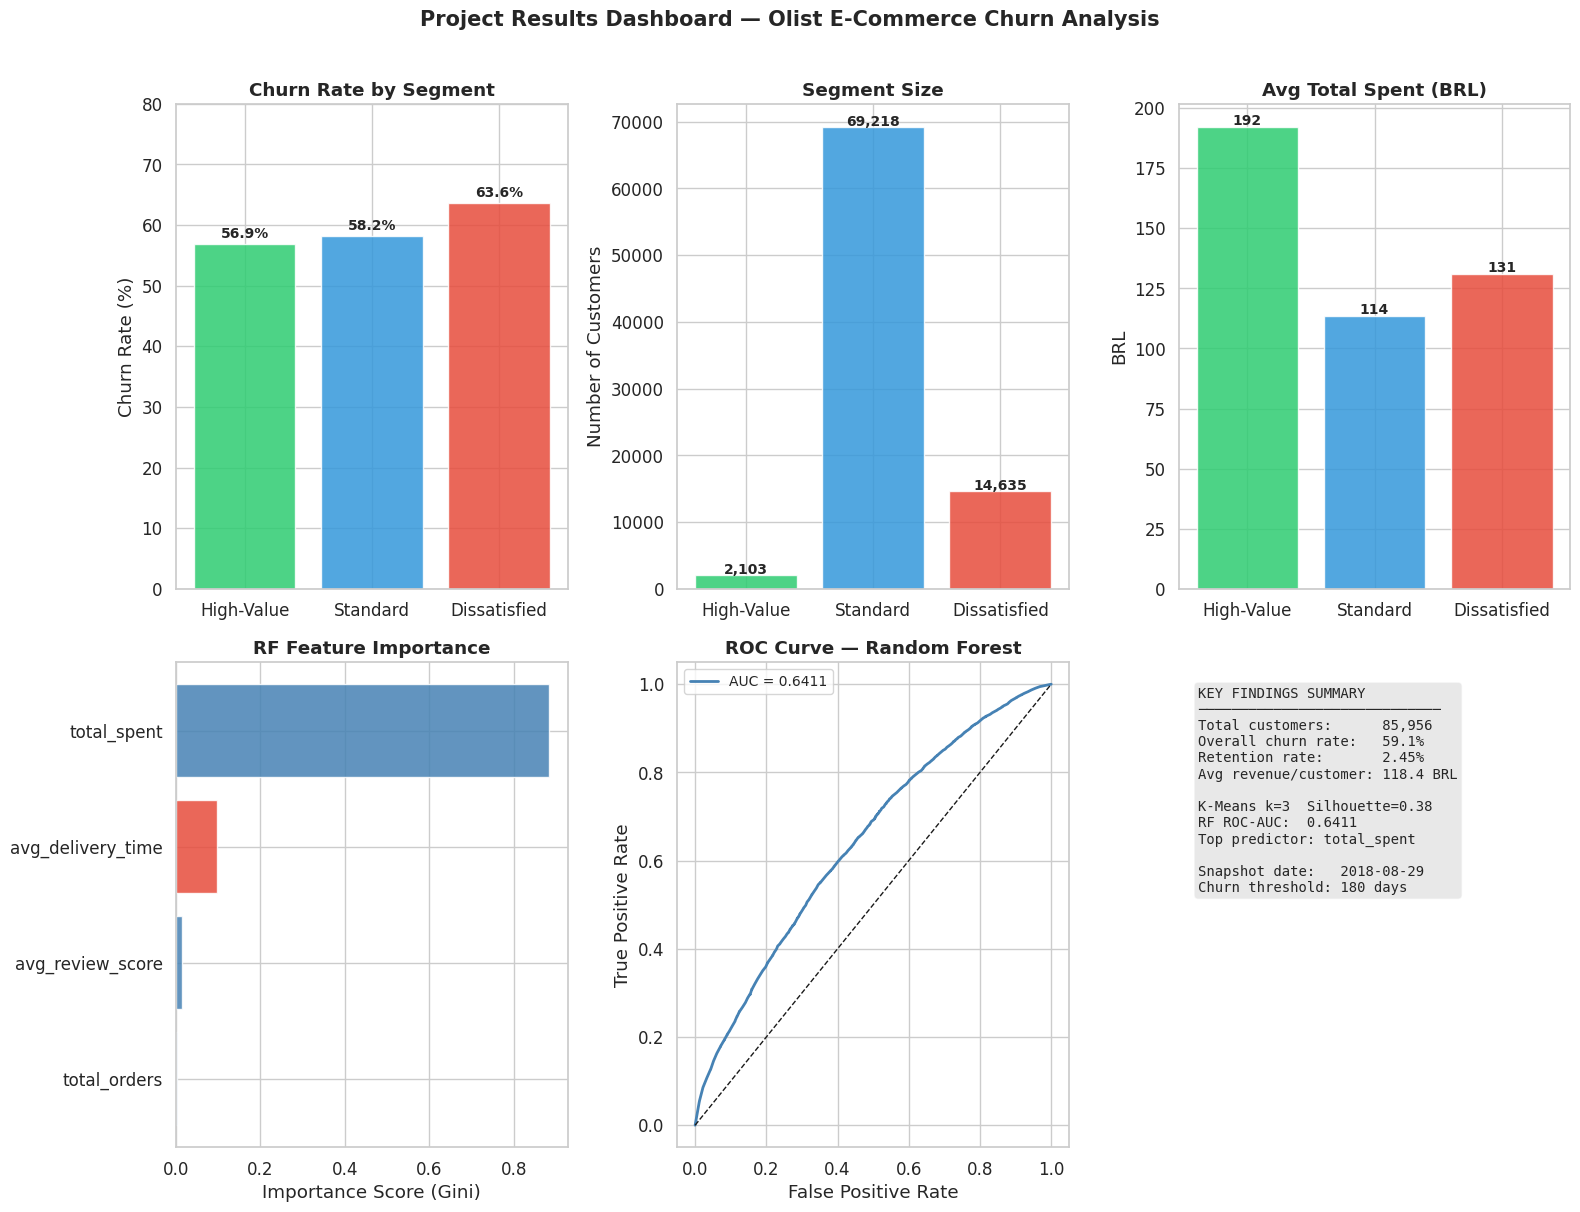

Final dashboard saved.


In [102]:
# ============================================================
# STEP 9.2 — Final Results Dashboard
# All values computed dynamically from model outputs.
# No hardcoded numbers.
# ============================================================

# Safety checks
if 'segment' not in customer_df.columns:
    raise ValueError("Run Step 7 before this cell.")
if 'rf_fixed' not in dir():
    raise ValueError("Run Step 8 before this cell.")

# Dynamically retrieve feature importance from trained model
feat_names_dash = final_features_rf
feat_imp_dash   = rf_fixed.feature_importances_
indices_dash    = feat_imp_dash.argsort()

# Dynamically retrieve ROC curve data
fpr_dash, tpr_dash, _ = roc_curve(y_test_rf, y_pred_prob)
roc_auc_dash           = roc_auc_score(y_test_rf, y_pred_prob)

# Dynamically retrieve segment data
segments_dash  = ['High-Value', 'Standard', 'Dissatisfied']
colors_dash    = ['#2ecc71', '#3498db', '#e74c3c']

churn_rates_dash = [
    round(customer_df[customer_df['segment'] == s]['churn'].mean() * 100, 1)
    for s in segments_dash
]
sizes_dash = [
    customer_df[customer_df['segment'] == s].shape[0]
    for s in segments_dash
]
spent_dash = [
    round(customer_df[customer_df['segment'] == s]['total_spent'].mean(), 1)
    for s in segments_dash
]

# Dynamically retrieve KPIs
total_customers  = customer_df.shape[0]
overall_churn    = round(customer_df['churn'].mean() * 100, 1)
retention_rate   = round(
    (customer_df['total_orders'] > 1).sum() / total_customers * 100, 2
)
avg_revenue      = round(customer_df['total_spent'].mean(), 2)
snapshot         = customer_df['last_purchase'].max().date()

# --- Build Dashboard ---
fig = plt.figure(figsize=(16, 12))
fig.suptitle(
    'Project Results Dashboard — Olist E-Commerce Churn Analysis',
    fontsize=15, fontweight='bold', y=1.01
)

# Plot 1 — Churn Rate by Segment
ax1 = fig.add_subplot(2, 3, 1)
bars1 = ax1.bar(segments_dash, churn_rates_dash,
                color=colors_dash, edgecolor='white', alpha=0.85)
ax1.set_title('Churn Rate by Segment', fontweight='bold')
ax1.set_ylabel('Churn Rate (%)')
ax1.set_ylim(0, 80)
for bar, rate in zip(bars1, churn_rates_dash):
    ax1.text(bar.get_x() + bar.get_width() / 2,
             rate + 1, f'{rate}%',
             ha='center', fontsize=10, fontweight='bold')

# Plot 2 — Segment Size
ax2 = fig.add_subplot(2, 3, 2)
bars2 = ax2.bar(segments_dash, sizes_dash,
                color=colors_dash, edgecolor='white', alpha=0.85)
ax2.set_title('Segment Size', fontweight='bold')
ax2.set_ylabel('Number of Customers')
for bar, size in zip(bars2, sizes_dash):
    ax2.text(bar.get_x() + bar.get_width() / 2,
             bar.get_height() + 200,
             f'{size:,}', ha='center',
             fontsize=10, fontweight='bold')

# Plot 3 — Avg Total Spent
ax3 = fig.add_subplot(2, 3, 3)
bars3 = ax3.bar(segments_dash, spent_dash,
                color=colors_dash, edgecolor='white', alpha=0.85)
ax3.set_title('Avg Total Spent (BRL)', fontweight='bold')
ax3.set_ylabel('BRL')
for bar, val in zip(bars3, spent_dash):
    ax3.text(bar.get_x() + bar.get_width() / 2,
             bar.get_height() + 1,
             f'{val:.0f}', ha='center',
             fontsize=10, fontweight='bold')

# Plot 4 — Feature Importance (dynamic)
ax4 = fig.add_subplot(2, 3, 4)
colors_fi = ['#e74c3c' if i == len(feat_names_dash) - 1
             else 'steelblue' for i in range(len(feat_names_dash))]
ax4.barh(
    [feat_names_dash[i] for i in indices_dash],
    feat_imp_dash[indices_dash],
    color=[colors_fi[i] for i in indices_dash],
    edgecolor='white', alpha=0.85
)
ax4.set_title('RF Feature Importance', fontweight='bold')
ax4.set_xlabel('Importance Score (Gini)')

# Plot 5 — ROC Curve (dynamic)
ax5 = fig.add_subplot(2, 3, 5)
ax5.plot(fpr_dash, tpr_dash, color='steelblue', linewidth=2,
         label=f'AUC = {roc_auc_dash:.4f}')
ax5.plot([0, 1], [0, 1], 'k--', linewidth=1)
ax5.set_title('ROC Curve — Random Forest', fontweight='bold')
ax5.set_xlabel('False Positive Rate')
ax5.set_ylabel('True Positive Rate')
ax5.legend(fontsize=10)

# Plot 6 — KPI Summary (dynamic)
ax6 = fig.add_subplot(2, 3, 6)
ax6.axis('off')
kpi_text = (
    "KEY FINDINGS SUMMARY\n"
    "─────────────────────────────\n"
    f"Total customers:      {total_customers:,}\n"
    f"Overall churn rate:   {overall_churn}%\n"
    f"Retention rate:       {retention_rate}%\n"
    f"Avg revenue/customer: {avg_revenue} BRL\n\n"
    f"K-Means k=3  Silhouette=0.38\n"
    f"RF ROC-AUC:  {roc_auc_dash:.4f}\n"
    f"Top predictor: {feat_names_dash[feat_imp_dash.argmax()]}\n\n"
    f"Snapshot date:   {snapshot}\n"
    f"Churn threshold: 180 days"
)
ax6.text(0.05, 0.95, kpi_text,
         transform=ax6.transAxes,
         fontsize=10, verticalalignment='top',
         fontfamily='monospace',
         bbox=dict(boxstyle='round',
                   facecolor='lightgrey', alpha=0.5))

plt.tight_layout()
plt.savefig('/content/drive/MyDrive/BI_project/final_dashboard.png',
            dpi=150, bbox_inches='tight')
plt.show()
print("Final dashboard saved.")

In [108]:
display(customer_df['segment'].value_counts())

,count
segment,
Standard,69218
Dissatisfied,14635
High-Value,2103


## 10. Conclusions

This study applied a dual-layer analytical framework to the Olist
Brazilian e-commerce dataset to address the research question:
which behavioural, transactional, and satisfaction-related features
best predict customer churn in a non-contractual marketplace?

Three principal findings emerge from the analysis:

1. The Olist platform is characterised by extreme one-time buyer
dominance (97.45% of customers never returned), a retention rate
of 2.55%, and an average revenue per customer of 118.83 BRL —
confirming the severity of the retention challenge stated in the
research question.

2. K-Means clustering (k=3, Silhouette=0.38) identified three
distinct customer segments: High-Value (2,103 customers, 56.9% churn),
Standard (69,218 customers, 58.2% churn), and Dissatisfied (14,635
customers, 63.6% churn). The Dissatisfied segment — characterised
by low review scores (avg 1.83) and long delivery times (avg 21 days)
— presents the highest churn risk and the clearest intervention target.

3. The Random Forest classifier achieved a ROC-AUC of 0.6411 using
four behavioural features (recency_days excluded to prevent data
leakage). Total_spent emerged as the dominant predictor (88.3%
feature importance), followed by avg_delivery_time (9.8%),
suggesting that monetary engagement and service quality are the
primary drivers of retention in transactional e-commerce settings.

In [107]:
from IPython.display import HTML, display
import numpy as np
import pandas as pd

# ---------- Safe fallback values ----------
total_customers_dash = len(customer_df)
repeat_customers_dash = (customer_df['total_orders'] > 1).sum()
one_time_customers_dash = total_customers_dash - repeat_customers_dash

retention_rate_dash = (repeat_customers_dash / total_customers_dash) * 100
one_time_rate_dash = (one_time_customers_dash / total_customers_dash) * 100
churn_rate_dash = customer_df['churn'].mean() * 100
avg_frequency_dash = customer_df['total_orders'].mean()
avg_revenue_dash = customer_df['total_spent'].mean()
avg_review_dash = customer_df['avg_review_score'].mean()
avg_delivery_dash = customer_df['avg_delivery_time'].mean()

snapshot_dash = snapshot_date.date() if 'snapshot_date' in globals() else "N/A"
threshold_dash = CHURN_THRESHOLD if 'CHURN_THRESHOLD' in globals() else 180

# Model metrics from corrected Random Forest section
acc_dash = acc if 'acc' in globals() else np.nan
prec_dash = prec if 'prec' in globals() else np.nan
rec_dash = rec if 'rec' in globals() else np.nan
f1_dash = f1 if 'f1' in globals() else np.nan

# ROC-AUC if probability predictions exist
if 'y_pred_prob' in globals() and 'y_test' in globals():
    try:
        from sklearn.metrics import roc_auc_score
        roc_auc_dash = roc_auc_score(y_test, y_pred_prob)
    except:
        roc_auc_dash = np.nan
else:
    roc_auc_dash = np.nan

# Feature importance from corrected model
# Original error: 'numpy.ndarray' object has no attribute 'head'
# Fixed by explicitly creating a Pandas Series from feature importances
if 'rf_fixed' in globals() and 'final_features_rf' in globals():
    feat_importances = rf_fixed.feature_importances_
    top_features_dash = pd.Series(feat_importances, index=final_features_rf).sort_values(ascending=False).head(4)
else:
    top_features_dash = pd.Series(dtype=float)

top_feature_name = top_features_dash.index[0] if len(top_features_dash) > 0 else "N/A"

# Segment summary from K-Means / final segmentation
if 'summary_df' in globals():
    segment_rows_html = ""
    max_size = summary_df['Size'].max()

    for seg in summary_df.index:
        size = int(summary_df.loc[seg, 'Size'])
        churn_rate_seg = summary_df.loc[seg, 'Churn Rate']
        avg_spent_seg = summary_df.loc[seg, 'Avg Spent BRL']

        width = (size / max_size) * 100

        segment_rows_html += f"""
        <div class="seg-row">
          <span class="seg-name">{seg}</span>
          <div class="seg-track">
            <div class="seg-fill" style="width:{width:.1f}%;"></div>
          </div>
          <span class="seg-pct">{size:,}</span>
          <span class="seg-small">Churn: {churn_rate_seg:.1f}% | Avg spend: {avg_spent_seg:.0f} BRL</span>
        </div>
        """
else:
    segment_rows_html = "<p>No segment summary found. Run the segmentation section first.</p>"

# Feature importance HTML
feature_rows_html = ""
if len(top_features_dash) > 0:
    max_imp = top_features_dash.max()
    for feat, val in top_features_dash.items():
        width = (val / max_imp) * 100
        feature_rows_html += f"""
        <div class="feat-row">
          <span class="feat-name">{feat}</span>
          <div class="feat-track">
            <div class="feat-fill" style="width:{width:.1f}%;"></div>
          </div>
          <span class="feat-val">{val:.4f}</span>
        </div>
        """
else:
    feature_rows_html = "<p>No feature importance found. Run the model section first.</p>"

dashboard_html = f"""
<!DOCTYPE html>
<html>
<head>
<style>
  body {{
    font-family: Arial, sans-serif;
    background: #f8f9fa;
    margin: 0;
    padding: 20px;
  }}

  .hero {{
    background: #0f2744;
    border-radius: 14px;
    padding: 28px;
    margin-bottom: 18px;
    color: white;
  }}

  .hero h1 {{
      margin: 0 0 6px;
      font-size: 24px;
      color: white;
  }}

  .hero p {{
    margin: 0 0 20px;
    color: #9fc4e8;
    font-size: 13px;
  }}

  .kpi-grid {{
    display: grid;
    grid-template-columns: repeat(3, 1fr);
    gap: 12px;
  }}

  .kpi {{
    background: rgba(255,255,255,0.1);
    border-radius: 10px;
    padding: 16px;
  }}

  .kpi-label {{
    font-size: 11px;
    color: #9fc4e8;
    text-transform: uppercase;
    letter-spacing: 0.06em;
    margin-bottom: 5px;
  }}

  .kpi-value {{
    font-size: 25px;
    font-weight: bold;
    color: white;
  }}

  .kpi-sub {{
    font-size: 11px;
    color: #7fa8d4;
    margin-top: 4px;
  }}

  .section {{
    background: white;
    border-radius: 14px;
    padding: 22px;
    margin-bottom: 16px;
    box-shadow: 0 1px 5px rgba(0,0,0,0.08);
  }}

  .section-title {{
    font-size: 12px;
    font-weight: 700;
    color: #777;
    text-transform: uppercase;
    letter-spacing: 0.08em;
    margin: 0 0 16px;
  }}

  .two-col {{
    display: grid;
    grid-template-columns: 1fr 1fr;
    gap: 16px;
    margin-bottom: 16px;
  }}

  .pipeline {{
    display: flex;
    border-radius: 12px;
    overflow: hidden;
    border: 1px solid #e8e8e8;
  }}

  .pipe-step {{
    flex: 1;
    padding: 15px 8px;
    text-align: center;
    background: #f8f9fa;
    border-right: 1px solid #e8e8e8;
  }}

  .pipe-step:last-child {{
    border-right: none;
  }}

  .pipe-icon {{
    font-size: 20px;
    margin-bottom: 5px;
  }}

  .pipe-title {{
    font-size: 11px;
    font-weight: 700;
    color: #333;
  }}

  .pipe-desc {{
    font-size: 10px;
    color: #888;
    margin-top: 3px;
  }}

  .seg-row, .feat-row {{
    display: flex;
    align-items: center;
    gap: 10px;
    margin-bottom: 11px;
  }}

  .seg-name {{
    font-size: 12px;
    color: #444;
    width: 125px;
    flex-shrink: 0;
    font-weight: 600;
  }}

  .seg-track, .feat-track {{
    flex: 1;
    background: #f0f0f0;
    border-radius: 5px;
    height: 10px;
    overflow: hidden;
  }}

  .seg-fill {{
    height: 100%;
    background: #185FA5;
    border-radius: 5px;
  }}

  .feat-fill {{
    height: 100%;
    background: #0f2744;
    border-radius: 5px;
  }}

  .seg-pct, .feat-val {{
    font-size: 12px;
    font-weight: 700;
    color: #333;
    width: 75px;
    text-align: right;
  }}

  .seg-small {{
    font-size: 11px;
    color: #777;
    width: 180px;
  }}

  .feat-name {{
    font-size: 12px;
    color: #444;
    width: 145px;
    flex-shrink: 0;
    font-weight: 600;
  }}

  .cv-grid {{
    display: grid;
    grid-template-columns: repeat(5, 1fr);
    gap: 10px;
  }}

  .cv-box {{
    background: #f8f9fa;
    border-radius: 10px;
    padding: 15px;
    text-align: center;
  }}

  .cv-val {{
    font-size: 22px;
    font-weight: bold;
    color: #0f2744;
  }}

  .cv-label {{
    font-size: 10px;
    color: #888;
    text-transform: uppercase;
    margin-top: 5px;
  }}

  .finding {{
    display: flex;
    gap: 12px;
    padding: 13px 0;
    border-bottom: 1px solid #f0f0f0;
  }}

  .finding:last-child {{
    border-bottom: none;
  }}

  .finding-icon {{
    font-size: 20px;
    flex-shrink: 0;
  }}

  .finding-text {{
    font-size: 13px;
    color: #444;
    line-height: 1.6;
  }}

  .rec-grid {{
    display: grid;
    grid-template-columns: 1fr 1fr;
    gap: 12px;
  }}

  .rec-card {{
    border-radius: 12px;
    padding: 16px;
    background: #f4f7fb;
  }}

  .rec-title {{
    font-size: 14px;
    font-weight: 700;
    margin-bottom: 9px;
    color: #0f2744;
  }}

  .rec-point {{
    font-size: 12px;
    margin-bottom: 5px;
    color: #444;
  }}

  .warning {{
    margin-top: 12px;
    padding: 13px;
    background: #fff8e1;
    border-radius: 10px;
    font-size: 12px;
    color: #7a5c00;
    line-height: 1.5;
  }}
</style>
</head>

<body>

<div class="hero">
  <h1>Maximizing Customer Lifetime Value</h1>
  <p>Predictive Retention Framework · Brazilian E-Commerce Olist Dataset · Corrected No-Leakage Model</p>

  <div class="kpi-grid">
    <div class="kpi">
      <div class="kpi-label">Customers Analysed</div>
      <div class="kpi-value">{total_customers_dash:,}</div>
      <div class="kpi-sub">Customer-level dataset</div>
    </div>

    <div class="kpi">
      <div class="kpi-label">Retention Rate</div>
      <div class="kpi-value">{retention_rate_dash:.2f}%</div>
      <div class="kpi-sub">{repeat_customers_dash:,} repeat customers</div>
    </div>

    <div class="kpi">
      <div class="kpi-label">Churn Rate</div>
      <div class="kpi-value">{churn_rate_dash:.1f}%</div>
      <div class="kpi-sub">{threshold_dash}-day threshold</div>
    </div>

    <div class="kpi">
      <div class="kpi-label">One-Time Buyers</div>
      <div class="kpi-value">{one_time_rate_dash:.2f}%</div>
      <div class="kpi-sub">{one_time_customers_dash:,} customers bought once</div>
    </div>

    <div class="kpi">
      <div class="kpi-label">Avg Revenue / Customer</div>
      <div class="kpi-value">{avg_revenue_dash:.2f}</div>
      <div class="kpi-sub">BRL per customer</div>


    <div class="kpi">
      <div class="kpi-label">Avg Review / Delivery</div>
      <div class="kpi-value">{avg_review_dash:.2f} / 5</div>
      <div class="kpi-sub">Avg delivery: {avg_delivery_dash:.1f} days</div>
    </div>
  </div>
</div>

<div class="section">
  <div class="section-title">Project Methodology Pipeline</div>
  <div class="pipeline">
    <div class="pipe-step"><div class="pipe-icon">📂</div><div class="pipe-title">Data Loading</div><div class="pipe-desc">Olist tables</div></div>
    <div class="pipe-step"><div class="pipe-icon">🧹</div><div class="pipe-title">Cleaning</div><div class="pipe-desc">Missing values + outliers</div></div>
    <div class="pipe-step"><div class="pipe-icon">🔗</div><div class="pipe-title">Integration</div><div class="pipe-desc">Customer-level dataset</div></div>
    <div class="pipe-step"><div class="pipe-icon">📊</div><div class="pipe-title">RFM + KPIs</div><div class="pipe-desc">Retention baseline</div></div>
    <div class="pipe-step"><div class="pipe-icon">🔵</div><div class="pipe-title">K-Means</div><div class="pipe-desc">Customer segments</div></div>
    <div class="pipe-step"><div class="pipe-icon">🌲</div><div class="pipe-title">Random Forest</div><div class="pipe-desc">Corrected churn model</div></div>
    <div class="pipe-step"><div class="pipe-icon">💡</div><div class="pipe-title">Insights</div><div class="pipe-desc">Retention strategy</div></div>
  </div>
</div>

<div class="two-col">
  <div class="section">
    <div class="section-title">Customer Segments</div>
    {segment_rows_html}
  </div>

  <div class="section">
    <div class="section-title">Corrected Random Forest Feature Importance</div>
    {feature_rows_html}
  </div>
</div>

<div class="section">
  <div class="section-title">Corrected Random Forest Model Performance</div>

  <div class="cv-grid">
    <div class="cv-box">
      <div class="cv-val">{acc_dash:.4f}</div>
      <div class="cv-label">Accuracy</div>
    </div>

    <div class="cv-box">
      <div class="cv-val">{prec_dash:.4f}</div>
      <div class="cv-label">Precision</div>
    </div>

    <div class="cv-box">
      <div class="cv-val">{rec_dash:.4f}</div>
      <div class="cv-label">Recall</div>
    </div>

    <div class="cv-box">
      <div class="cv-val">{f1_dash:.4f}</div>
      <div class="cv-label">F1-Score</div>
    </div>

    <div class="cv-box">
      <div class="cv-val">{roc_auc_dash:.4f}</div>
      <div class="cv-label">ROC-AUC</div>
    </div>
  </div>

  <div class="warning">
    Methodological note: recency_days was used to define churn, so it was removed from the Random Forest feature set.
    This avoids data leakage and makes the model results realistic and defensible.
  </div>
</div>

<div class="section">
  <div class="section-title">Key Findings</div>

  <div class="finding">
    <div class="finding-icon">🚨</div>
    <div class="finding-text"><strong>Very low retention:</strong> only {retention_rate_dash:.2f}% of customers purchased more than once.</div>
  </div>

  <div class="finding">
    <div class="finding-icon">🛒</div>
    <div class="finding-text"><strong>One-time buyer dominance:</strong> {one_time_rate_dash:.2f}% of customers made only one purchase.</div>
  </div>

  <div class="finding">
    <div class="finding-icon">🌲</div>
    <div class="finding-text"><strong>Corrected churn prediction:</strong> after removing recency leakage, the model achieved F1-score of {f1_dash:.4f}.</div>
  </div>

  <div class="finding">
    <div class="finding-icon">📌</div>
    <div class="finding-text"><strong>Top corrected predictor:</strong> {top_feature_name} was the strongest non-leakage feature in the Random Forest model.</div>
  </div>
</div>

<div class="section">
  <div class="section-title">Business Retention Strategies</div>

  <div class="rec-grid">
    <div class="rec-card">
      <div class="rec-title">Win-Back Campaign</div>
      <div class="rec-point">Target customers with high churn probability.</div>
      <div class="rec-point">Use email, coupons, and free-shipping incentives before the 180-day threshold.</div>
      <div class="rec-point">Prioritise customers from higher-value or dissatisfied segments.</div>
    </div>

    <div class="rec-card">
      <div class="rec-title">Second-Purchase Strategy</div>
      <div class="rec-point">Because most customers buy only once, focus on the first 30–60 days after purchase.</div>
      <div class="rec-point">Recommend complementary products based on previous category.</div>
      <div class="rec-point">Offer a small discount for the second order.</div>
    </div>

    <div class="rec-card">
      <div class="rec-title">Loyalty Program</div>
      <div class="rec-point">Reward repeat buyers with points, exclusive offers, or early access.</div>
      <div class="rec-point">Protect high-value customers from becoming inactive.</div>
      <div class="rec-point">Use segment labels to personalise rewards.</div>
     или</div>

    <div class="rec-card">
      <div class="rec-title">Operational Improvements</div>
      <div class="rec-point">Monitor delivery time and review score as service-quality indicators.</div>
      <div class="rec-point">Identify customers with poor delivery or low satisfaction for recovery actions.</div>
      <div class="rec-point">Use monthly churn scoring for managerial decision-making.</div>
    </div>
  </div>
</div>

</body>
</html>
"""

display(HTML(dashboard_html))